# CS781 Capstone · Phase 4 · Court Judgment Prediction (CJPE)

In [1]:
import os, sys, subprocess, json, glob, shutil
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "regex", "huggingface_hub"], check=False)
ON_KAGGLE = os.path.exists("/kaggle/working")
WORK = "/kaggle/working" if ON_KAGGLE else os.getcwd()
os.makedirs(f"{WORK}/p4cjpe/phase1_models", exist_ok=True); os.makedirs(f"{WORK}/tests", exist_ok=True)
os.chdir(WORK); sys.path.insert(0, WORK)
import torch
N_GPU = torch.cuda.device_count()
print("torch", torch.__version__, "| GPUs:", [torch.cuda.get_device_name(i) for i in range(N_GPU)] or "NONE (enable GPU!)",
      "| CPUs:", os.cpu_count())

torch 2.11.0+cu128 | GPUs: ['Tesla T4', 'Tesla T4'] | CPUs: 4


## Pipeline code (written to `p4cjpe/`; nothing to edit)

In [2]:
%%writefile {WORK}/p4cjpe/phase1_models/arch_a.py
"""Architecture A: decoder-only LLaMA-style (GQA, RoPE, SwiGLU).

Copied VERBATIM from the Phase-1 notebook that produced the checkpoint (decoder-only-fine-tuned.ipynb / decoder-only-transformer-llama-style.ipynb),
so parameter names match model_final.pt. Do not edit: Phase-2 code wraps these modules instead."""
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
from .common import RMSNorm, RotaryEmbedding, SwiGLU, _ffn_hidden, init_weights_, lm_loss

class GQAttention(nn.Module):
    def __init__(self, d_model, n_head, n_kv_head, dropout=0.0, bias=False):
        super().__init__()
        assert d_model % n_head == 0 and n_head % n_kv_head == 0
        self.n_head, self.n_kv, self.hd = n_head, n_kv_head, d_model // n_head
        self.wq = nn.Linear(d_model, n_head * self.hd, bias=bias)
        self.wkv = nn.Linear(d_model, 2 * n_kv_head * self.hd, bias=bias)
        self.proj = nn.Linear(n_head * self.hd, d_model, bias=bias)
        self.dropout = dropout
        self.resid_drop = nn.Dropout(dropout)

    def forward(self, x, rope, pos0=0, cache=None):
        B, T, C = x.shape
        q = self.wq(x).view(B, T, self.n_head, self.hd).transpose(1, 2)
        k, v = self.wkv(x).view(B, T, 2, self.n_kv, self.hd).permute(2, 0, 3, 1, 4)
        q, k = rope(q, pos0), rope(k, pos0)
        if cache is not None:
            if "k" in cache:
                assert T == 1, "cached decoding feeds one token at a time"
                k, v = torch.cat([cache["k"], k], 2), torch.cat([cache["v"], v], 2)
            cache["k"], cache["v"] = k, v
        if self.n_kv != self.n_head:
            rep = self.n_head // self.n_kv
            k, v = k.repeat_interleave(rep, dim=1), v.repeat_interleave(rep, dim=1)
        y = F.scaled_dot_product_attention(q, k, v, is_causal=T > 1,
                                           dropout_p=self.dropout if self.training else 0.0)
        return self.resid_drop(self.proj(y.transpose(1, 2).reshape(B, T, -1)))

class Block(nn.Module):
    def __init__(self, d_model, n_head, n_kv_head, ffn_hidden, dropout, bias):
        super().__init__()
        self.norm1, self.norm2 = RMSNorm(d_model), RMSNorm(d_model)
        self.attn = GQAttention(d_model, n_head, n_kv_head, dropout, bias)
        self.ffn = SwiGLU(d_model, ffn_hidden, dropout, bias)

    def forward(self, x, rope, pos0=0, cache=None):
        x = x + self.attn(self.norm1(x), rope, pos0, cache)
        return x + self.ffn(self.norm2(x))

class LlamaLM(nn.Module):
    def __init__(self, vocab_size, block_size, pad_id=None, n_layer=12, n_head=10, n_kv_head=2, d_model=640,
                 ffn_mult=8 / 3, dropout=0.0, rope_theta=10000.0, tie_weights=True, bias=False, **kw):
        super().__init__()
        if kw:
            print(f"[LlamaLM] ignoring unknown config keys: {sorted(kw)}")
        self.block_size, self.pad_id, self.n_layer = block_size, pad_id, n_layer
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.drop = nn.Dropout(dropout)
        self.rope = RotaryEmbedding(d_model // n_head, block_size, rope_theta)
        hidden = _ffn_hidden(d_model, ffn_mult)
        self.blocks = nn.ModuleList([Block(d_model, n_head, n_kv_head, hidden, dropout, bias) for _ in range(n_layer)])
        self.norm_f = RMSNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        init_weights_(self, n_layer)
        if tie_weights:
            self.lm_head.weight = self.tok_emb.weight

    def forward(self, idx, targets=None, pos0=0, caches=None, last_only=False):
        B, T = idx.shape
        assert pos0 + T <= self.block_size, f"position {pos0 + T} > block_size {self.block_size}"
        x = self.drop(self.tok_emb(idx))
        for i, blk in enumerate(self.blocks):
            x = blk(x, self.rope, pos0, None if caches is None else caches[i])
        x = self.norm_f(x)
        if last_only:
            x = x[:, -1:]
        logits = self.lm_head(x)
        loss = None if targets is None else lm_loss(logits, targets)
        return logits, loss

MODEL_CLASS = LlamaLM

Writing /kaggle/working/p4cjpe/phase1_models/arch_a.py


In [3]:
%%writefile {WORK}/p4cjpe/phase1_models/arch_b.py
"""Architecture B: encoder-decoder.

Copied VERBATIM from the Phase-1 notebook that produced the checkpoint (B/notebookc976077ad3.ipynb),
so parameter names match model_final.pt. Do not edit: Phase-2 code wraps these modules instead."""
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
from .common import RMSNorm, RotaryEmbedding, SwiGLU, _ffn_hidden, init_weights_, lm_loss

class SelfAttention(nn.Module):
    def __init__(self, d_model, n_head, dropout=0.0, bias=False):
        super().__init__()
        assert d_model % n_head == 0
        self.n_head, self.hd = n_head, d_model // n_head
        self.qkv = nn.Linear(d_model, 3 * d_model, bias=bias)
        self.proj = nn.Linear(d_model, d_model, bias=bias)
        self.dropout = dropout
        self.resid_drop = nn.Dropout(dropout)

    def forward(self, x, rope, pos0=0, key_mask=None, causal=False, cache=None):
        B, T, C = x.shape
        q, k, v = self.qkv(x).view(B, T, 3, self.n_head, self.hd).permute(2, 0, 3, 1, 4)
        q, k = rope(q, pos0), rope(k, pos0)
        if cache is not None:
            if "k" in cache:
                assert T == 1, "cached decoding feeds one token at a time"
                k, v = torch.cat([cache["k"], k], 2), torch.cat([cache["v"], v], 2)
            cache["k"], cache["v"] = k, v
        mask = None if key_mask is None else key_mask[:, None, None, :]
        y = F.scaled_dot_product_attention(q, k, v, attn_mask=mask, is_causal=causal and T > 1 and mask is None,
                                           dropout_p=self.dropout if self.training else 0.0)
        return self.resid_drop(self.proj(y.transpose(1, 2).reshape(B, T, C)))

class CrossAttention(nn.Module):
    def __init__(self, d_model, n_head, dropout=0.0, bias=False):
        super().__init__()
        self.n_head, self.hd = n_head, d_model // n_head
        self.q = nn.Linear(d_model, d_model, bias=bias)
        self.kv = nn.Linear(d_model, 2 * d_model, bias=bias)
        self.proj = nn.Linear(d_model, d_model, bias=bias)
        self.dropout = dropout
        self.resid_drop = nn.Dropout(dropout)

    def forward(self, x, memory, mem_mask, cache=None):
        B, T, C = x.shape
        q = self.q(x).view(B, T, self.n_head, self.hd).transpose(1, 2)
        if cache is not None and "ck" in cache:
            k, v = cache["ck"], cache["cv"]
        else:
            S = memory.size(1)
            k, v = self.kv(memory).view(B, S, 2, self.n_head, self.hd).permute(2, 0, 3, 1, 4)
            if cache is not None:
                cache["ck"], cache["cv"] = k, v
        mask = None if mem_mask is None else mem_mask[:, None, None, :]
        y = F.scaled_dot_product_attention(q, k, v, attn_mask=mask,
                                           dropout_p=self.dropout if self.training else 0.0)
        return self.resid_drop(self.proj(y.transpose(1, 2).reshape(B, T, C)))

class EncoderBlock(nn.Module):
    def __init__(self, d_model, n_head, ffn_hidden, dropout, bias):
        super().__init__()
        self.norm1, self.norm2 = RMSNorm(d_model), RMSNorm(d_model)
        self.attn = SelfAttention(d_model, n_head, dropout, bias)
        self.ffn = SwiGLU(d_model, ffn_hidden, dropout, bias)

    def forward(self, x, rope, key_mask):
        x = x + self.attn(self.norm1(x), rope, 0, key_mask=key_mask, causal=False)
        return x + self.ffn(self.norm2(x))

class DecoderBlock(nn.Module):
    def __init__(self, d_model, n_head, ffn_hidden, dropout, bias):
        super().__init__()
        self.norm1, self.norm2, self.norm3 = RMSNorm(d_model), RMSNorm(d_model), RMSNorm(d_model)
        self.self_attn = SelfAttention(d_model, n_head, dropout, bias)
        self.cross_attn = CrossAttention(d_model, n_head, dropout, bias)
        self.ffn = SwiGLU(d_model, ffn_hidden, dropout, bias)

    def forward(self, x, rope, memory, mem_mask, pos0=0, cache=None):
        x = x + self.self_attn(self.norm1(x), rope, pos0, causal=True, cache=cache)
        x = x + self.cross_attn(self.norm2(x), memory, mem_mask, cache=cache)
        return x + self.ffn(self.norm3(x))

class EncDecLM(nn.Module):
    def __init__(self, vocab_size, enc_block, dec_block, pad_id=None, n_enc_layer=6, n_dec_layer=6,
                 n_head=9, d_model=576, ffn_mult=8 / 3, dropout=0.0, rope_theta=10000.0, bias=False, **kw):
        super().__init__()
        if kw:
            print(f"[EncDecLM] ignoring unknown config keys: {sorted(kw)}")
        self.enc_block, self.dec_block, self.pad_id = enc_block, dec_block, pad_id
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.drop = nn.Dropout(dropout)
        hd = d_model // n_head
        self.enc_rope = RotaryEmbedding(hd, enc_block, rope_theta)
        self.dec_rope = RotaryEmbedding(hd, dec_block, rope_theta)
        hidden = _ffn_hidden(d_model, ffn_mult)
        self.enc_blocks = nn.ModuleList([EncoderBlock(d_model, n_head, hidden, dropout, bias) for _ in range(n_enc_layer)])
        self.dec_blocks = nn.ModuleList([DecoderBlock(d_model, n_head, hidden, dropout, bias) for _ in range(n_dec_layer)])
        self.enc_norm, self.dec_norm = RMSNorm(d_model), RMSNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        init_weights_(self, n_enc_layer + n_dec_layer)
        self.lm_head.weight = self.tok_emb.weight

    def encode(self, src, src_mask=None):
        assert src.size(1) <= self.enc_block, f"source length {src.size(1)} > enc_block {self.enc_block}"
        if src_mask is not None and bool(src_mask.all()):
            src_mask = None
        x = self.drop(self.tok_emb(src))
        for blk in self.enc_blocks:
            x = blk(x, self.enc_rope, src_mask)
        return self.enc_norm(x)

    def decode(self, dec_in, memory, mem_mask=None, pos0=0, caches=None, last_only=False):
        assert pos0 + dec_in.size(1) <= self.dec_block, f"decoder position {pos0 + dec_in.size(1)} > dec_block"
        if mem_mask is not None and bool(mem_mask.all()):
            mem_mask = None
        x = self.drop(self.tok_emb(dec_in))
        for i, blk in enumerate(self.dec_blocks):
            x = blk(x, self.dec_rope, memory, mem_mask, pos0, None if caches is None else caches[i])
        x = self.dec_norm(x)
        if last_only:
            x = x[:, -1:]
        return self.lm_head(x)

    def forward(self, src, src_mask, dec_in, targets=None):
        memory = self.encode(src, src_mask)
        logits = self.decode(dec_in, memory, src_mask)
        loss = None if targets is None else lm_loss(logits, targets)
        return logits, loss

MODEL_CLASS = EncDecLM

Writing /kaggle/working/p4cjpe/phase1_models/arch_b.py


In [4]:
%%writefile {WORK}/p4cjpe/phase1_models/arch_c.py
"""Architecture C: encoder/hybrid prefix-LM + MLM (UniLM-style).

Copied VERBATIM from the Phase-1 notebook that produced the checkpoint (C/encoder-hybrid.ipynb),
so parameter names match model_final.pt. Do not edit: Phase-2 code wraps these modules instead."""
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
from .common import RMSNorm, RotaryEmbedding, SwiGLU, _ffn_hidden, init_weights_, lm_loss

class HybridSelfAttention(nn.Module):
    def __init__(self, d_model, n_head, dropout=0.0, bias=False):
        super().__init__()
        assert d_model % n_head == 0
        self.n_head, self.hd = n_head, d_model // n_head
        self.qkv = nn.Linear(d_model, 3 * d_model, bias=bias)
        self.proj = nn.Linear(d_model, d_model, bias=bias)
        self.dropout = dropout
        self.resid_drop = nn.Dropout(dropout)

    def forward(self, x, rope, attn_mask=None, causal=True, pos0=0, cache=None):
        B, T, C = x.shape
        q, k, v = self.qkv(x).view(B, T, 3, self.n_head, self.hd).permute(2, 0, 3, 1, 4)
        q, k = rope(q, pos0), rope(k, pos0)
        if cache is not None:
            if "k" in cache:
                assert T == 1, "cached decoding feeds one token at a time"
                k, v = torch.cat([cache["k"], k], 2), torch.cat([cache["v"], v], 2)
            cache["k"], cache["v"] = k, v
        y = F.scaled_dot_product_attention(q, k, v, attn_mask=attn_mask,
                                           is_causal=causal and attn_mask is None and T > 1,
                                           dropout_p=self.dropout if self.training else 0.0)
        return self.resid_drop(self.proj(y.transpose(1, 2).reshape(B, T, C)))

class Block(nn.Module):
    def __init__(self, d_model, n_head, ffn_hidden, dropout, bias):
        super().__init__()
        self.norm1, self.norm2 = RMSNorm(d_model), RMSNorm(d_model)
        self.attn = HybridSelfAttention(d_model, n_head, dropout, bias)
        self.ffn = SwiGLU(d_model, ffn_hidden, dropout, bias)

    def forward(self, x, rope, attn_mask, causal, pos0=0, cache=None):
        x = x + self.attn(self.norm1(x), rope, attn_mask, causal, pos0, cache)
        return x + self.ffn(self.norm2(x))

class HybridLM(nn.Module):
    def __init__(self, vocab_size, block_size, pad_id=None, n_layer=10, n_head=10, d_model=640, ffn_mult=8 / 3,
                 dropout=0.0, rope_theta=10000.0, tie_weights=True, bias=False, n_segments=3, **kw):
        super().__init__()
        if kw:
            print(f"[HybridLM] ignoring unknown config keys: {sorted(kw)}")
        self.block_size, self.pad_id, self.n_layer = block_size, pad_id, n_layer
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.seg_emb = nn.Embedding(n_segments, d_model)
        self.drop = nn.Dropout(dropout)
        self.rope = RotaryEmbedding(d_model // n_head, block_size, rope_theta)
        hidden = _ffn_hidden(d_model, ffn_mult)
        self.blocks = nn.ModuleList([Block(d_model, n_head, hidden, dropout, bias) for _ in range(n_layer)])
        self.norm_f = RMSNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        init_weights_(self, n_layer)
        nn.init.zeros_(self.seg_emb.weight)
        if tie_weights:
            self.lm_head.weight = self.tok_emb.weight

    @staticmethod
    def hybrid_mask(prefix_len, T):
        pos = torch.arange(T, device=prefix_len.device)
        in_prefix = pos[None, None, :] < prefix_len[:, None, None]
        causal = pos[None, :, None] >= pos[None, None, :]
        return (in_prefix | causal)[:, None]

    def forward(self, idx, prefix_len=None, seg=None, targets=None, pos0=0, caches=None, last_only=False):
        B, T = idx.shape
        assert pos0 + T <= self.block_size, f"position {pos0 + T} > block_size {self.block_size}"
        if prefix_len is None:
            prefix_len = torch.zeros(B, dtype=torch.long, device=idx.device)
        prefix_len = prefix_len.to(idx.device).long().clamp(0, T)
        if bool((prefix_len == 0).all()):
            attn_mask, causal = None, True
        elif bool((prefix_len == T).all()):
            attn_mask, causal = None, False
        else:
            attn_mask, causal = self.hybrid_mask(prefix_len, T), False
        if seg is None:
            seg = (torch.arange(T, device=idx.device)[None, :] >= prefix_len[:, None]).long()
        x = self.drop(self.tok_emb(idx) + self.seg_emb(seg))
        for i, blk in enumerate(self.blocks):
            x = blk(x, self.rope, attn_mask, causal, pos0, None if caches is None else caches[i])
        x = self.norm_f(x)
        if last_only:
            x = x[:, -1:]
        logits = self.lm_head(x)
        loss = None if targets is None else lm_loss(logits, targets)
        return logits, loss

MODEL_CLASS = HybridLM

Writing /kaggle/working/p4cjpe/phase1_models/arch_c.py


In [5]:
%%writefile {WORK}/p4cjpe/phase1_models/arch_d.py
"""Architecture D: efficient decoder, sliding-window attention + MQA.

Copied VERBATIM from the Phase-1 notebook that produced the checkpoint (D/notebook7e00370b82.ipynb),
so parameter names match model_final.pt. Do not edit: Phase-2 code wraps these modules instead."""
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
from .common import RMSNorm, RotaryEmbedding, SwiGLU, _ffn_hidden, init_weights_, lm_loss

class LocalMQAttention(nn.Module):
    def __init__(self, d_model, n_head, n_kv_head, window, dropout=0.0, bias=False):
        super().__init__()
        assert d_model % n_head == 0 and n_head % n_kv_head == 0
        self.n_head, self.n_kv, self.hd, self.window = n_head, n_kv_head, d_model // n_head, window
        self.wq = nn.Linear(d_model, n_head * self.hd, bias=bias)
        self.wkv = nn.Linear(d_model, 2 * n_kv_head * self.hd, bias=bias)
        self.proj = nn.Linear(n_head * self.hd, d_model, bias=bias)
        self.dropout = dropout
        self.resid_drop = nn.Dropout(dropout)
        self._mask_cache = {}

    def _block_mask(self, nb, device):
        key = (nb, str(device))
        m = self._mask_cache.get(key)
        if m is None:
            W = self.window
            a = torch.arange(W, device=device)[:, None]
            b = torch.arange(2 * W, device=device)[None, :]
            keep = ((b > a) & (b <= a + W))[None].repeat(nb, 1, 1)
            keep[0, :, :W] = False
            m = keep[None, None].expand(1, self.n_head, nb, W, 2 * W).reshape(1, self.n_head * nb, W, 2 * W)
            self._mask_cache = {key: m}
        return m

    def _blocked(self, q, k, v):
        B, H, T, hd = q.shape
        W, Hkv = self.window, k.size(1)
        Tp = -(-T // W) * W
        if Tp != T:
            q, k, v = (F.pad(t, (0, 0, 0, Tp - T)) for t in (q, k, v))
        nb = Tp // W
        k = F.pad(k, (0, 0, W, 0)).unfold(2, 2 * W, W).transpose(-1, -2)
        v = F.pad(v, (0, 0, W, 0)).unfold(2, 2 * W, W).transpose(-1, -2)
        rep = H // Hkv
        k = k[:, :, None].expand(B, Hkv, rep, nb, 2 * W, hd).reshape(B, H * nb, 2 * W, hd)
        v = v[:, :, None].expand(B, Hkv, rep, nb, 2 * W, hd).reshape(B, H * nb, 2 * W, hd)
        qb = q.reshape(B, H * nb, W, hd)
        y = F.scaled_dot_product_attention(qb, k, v, attn_mask=self._block_mask(nb, q.device),
                                           dropout_p=self.dropout if self.training else 0.0)
        return y.reshape(B, H, Tp, hd)[:, :, :T]

    def forward(self, x, rope, pos0=0, cache=None):
        B, T, C = x.shape
        q = self.wq(x).view(B, T, self.n_head, self.hd).transpose(1, 2)
        k, v = self.wkv(x).view(B, T, 2, self.n_kv, self.hd).permute(2, 0, 3, 1, 4)
        q, k = rope(q, pos0), rope(k, pos0)
        if cache is not None and "k" in cache:
            assert T == 1, "cached decoding feeds one token at a time"
            k = torch.cat([cache["k"], k], 2)[:, :, -self.window:]
            v = torch.cat([cache["v"], v], 2)[:, :, -self.window:]
            cache["k"], cache["v"] = k, v
            rep = self.n_head // self.n_kv
            y = F.scaled_dot_product_attention(q, k.repeat_interleave(rep, 1), v.repeat_interleave(rep, 1))
        else:
            y = self._blocked(q, k, v)
            if cache is not None:
                cache["k"], cache["v"] = k[:, :, -self.window:], v[:, :, -self.window:]
        return self.resid_drop(self.proj(y.transpose(1, 2).reshape(B, T, -1)))

class Block(nn.Module):
    def __init__(self, d_model, n_head, n_kv_head, window, ffn_hidden, dropout, bias):
        super().__init__()
        self.norm1, self.norm2 = RMSNorm(d_model), RMSNorm(d_model)
        self.attn = LocalMQAttention(d_model, n_head, n_kv_head, window, dropout, bias)
        self.ffn = SwiGLU(d_model, ffn_hidden, dropout, bias)

    def forward(self, x, rope, pos0=0, cache=None):
        x = x + self.attn(self.norm1(x), rope, pos0, cache)
        return x + self.ffn(self.norm2(x))

class EfficientLM(nn.Module):
    def __init__(self, vocab_size, block_size, window=256, pad_id=None, n_layer=12, n_head=10, n_kv_head=1,
                 d_model=640, ffn_mult=8 / 3, dropout=0.0, rope_theta=10000.0, rope_max_len=8192,
                 tie_weights=True, bias=False, **kw):
        super().__init__()
        if kw:
            print(f"[EfficientLM] ignoring unknown config keys: {sorted(kw)}")
        self.block_size, self.window, self.pad_id, self.n_layer = block_size, window, pad_id, n_layer
        self.max_pos = max(rope_max_len, block_size)
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.drop = nn.Dropout(dropout)
        self.rope = RotaryEmbedding(d_model // n_head, self.max_pos, rope_theta)
        hidden = _ffn_hidden(d_model, ffn_mult)
        self.blocks = nn.ModuleList([Block(d_model, n_head, n_kv_head, window, hidden, dropout, bias)
                                     for _ in range(n_layer)])
        self.norm_f = RMSNorm(d_model)
        self.lm_head = nn.Linear(d_model, vocab_size, bias=False)
        init_weights_(self, n_layer)
        if tie_weights:
            self.lm_head.weight = self.tok_emb.weight

    def forward(self, idx, targets=None, pos0=0, caches=None, last_only=False):
        x = self.drop(self.tok_emb(idx))
        for i, blk in enumerate(self.blocks):
            x = blk(x, self.rope, pos0, None if caches is None else caches[i])
        x = self.norm_f(x)
        if last_only:
            x = x[:, -1:]
        logits = self.lm_head(x)
        loss = None if targets is None else lm_loss(logits, targets)
        return logits, loss

MODEL_CLASS = EfficientLM

Writing /kaggle/working/p4cjpe/phase1_models/arch_d.py


In [6]:
%%writefile {WORK}/p4cjpe/phase1_models/common.py
"""Shared building blocks (RMSNorm, RoPE, SwiGLU, init).

Copied VERBATIM from the Phase-1 notebook that produced the checkpoint (identical in A/B/C/D notebooks, cell 19),
so parameter names match model_final.pt. Do not edit: Phase-2 code wraps these modules instead."""
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

def _ffn_hidden(d_model, mult, multiple_of=64):
    h = int(mult * d_model)
    return multiple_of * ((h + multiple_of - 1) // multiple_of)

class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-6):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))

    def forward(self, x):
        xf = x.float()
        xf = xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + self.eps)
        return (xf * self.weight.float()).type_as(x)

class RotaryEmbedding(nn.Module):
    def __init__(self, head_dim, max_len, theta=10000.0):
        super().__init__()
        assert head_dim % 2 == 0, "RoPE needs an even head_dim"
        inv_freq = 1.0 / theta ** (torch.arange(0, head_dim, 2).float() / head_dim)
        freqs = torch.outer(torch.arange(max_len).float(), inv_freq)
        self.register_buffer("cos", freqs.cos(), persistent=False)
        self.register_buffer("sin", freqs.sin(), persistent=False)

    def forward(self, x, pos0=0):
        T = x.size(-2)
        assert pos0 + T <= self.cos.size(0), f"position {pos0 + T} > RoPE table {self.cos.size(0)}"
        cos, sin = self.cos[pos0:pos0 + T], self.sin[pos0:pos0 + T]
        x1, x2 = x.float().chunk(2, dim=-1)
        return torch.cat([x1 * cos - x2 * sin, x1 * sin + x2 * cos], dim=-1).type_as(x)

class SwiGLU(nn.Module):
    def __init__(self, d_model, hidden, dropout=0.0, bias=False):
        super().__init__()
        self.w12 = nn.Linear(d_model, 2 * hidden, bias=bias)
        self.proj = nn.Linear(hidden, d_model, bias=bias)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        a, b = self.w12(x).chunk(2, dim=-1)
        return self.drop(self.proj(F.silu(a) * b))

def init_weights_(model, n_layer):
    for m in model.modules():
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
    for name, p in model.named_parameters():
        if name.endswith("proj.weight"):
            nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * n_layer))

def lm_loss(logits, targets):
    return F.cross_entropy(logits.float().view(-1, logits.size(-1)), targets.reshape(-1), ignore_index=-100)

Writing /kaggle/working/p4cjpe/phase1_models/common.py


In [7]:
%%writefile {WORK}/p4cjpe/phase1_models/__init__.py
from .arch_a import LlamaLM
from .arch_b import EncDecLM
from .arch_c import HybridLM
from .arch_d import EfficientLM

MODEL_CLASSES = {c.__name__: c for c in (LlamaLM, EncDecLM, HybridLM, EfficientLM)}

Writing /kaggle/working/p4cjpe/phase1_models/__init__.py


In [8]:
%%writefile {WORK}/p4cjpe/__init__.py
"""CS781 Phase 4: Court Judgment Prediction (CJPE) on the Phase-1 legal language models."""

Writing /kaggle/working/p4cjpe/__init__.py


In [9]:
%%writefile {WORK}/p4cjpe/tokenizer.py
"""Byte-level BPE tokenizer from Phase 1 (load-only copy) + character offsets for NER.

Phase 1 trained the merges; here we only *load* them (same ids as pretraining) and add
`encode_with_offsets`, which returns for every token the character span it covers in the original text.

Offsets are computed per pre-token: the regex gives each pre-token's char span, BPE splits the pre-token's
UTF-8 bytes into tokens, and a byte->char table maps every token's byte range back to characters.
"""
import hashlib
import json
import os
import pickle
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import regex as re_u

SPECIAL_TOKENS = ["<|endoftext|>", "<|pad|>", "<|bos|>", "<|sep|>", "<|mask|>"]

FINE_PUNCT_PATTERN = (r"""'(?:[sdmt]|ll|ve|re)| ?\p{L}+| ?\p{N}{1,3}| ?[^\s\p{L}\p{N}]|\s*[\r\n]+|\s+(?!\S)|\s+""")

def _merge_ids(ids, pair, new_id):
    out, i, n = [], 0, len(ids)
    a, b = pair
    while i < n:
        if i < n - 1 and ids[i] == a and ids[i + 1] == b:
            out.append(new_id); i += 2
        else:
            out.append(ids[i]); i += 1
    return out

@dataclass
class Encoded:
    ids: list
    starts: list
    ends: list

class BPETokenizer:
    def __init__(self, merges, pattern, specials=SPECIAL_TOKENS, fine_punct=False):
        self.base_pattern = pattern
        self.fine_punct = fine_punct
        self.pattern = FINE_PUNCT_PATTERN if fine_punct else pattern
        self.pat = re_u.compile(self.pattern)
        self.merges = [tuple(m) for m in merges]
        self.specials = list(specials)
        self.ranks = {p: i for i, p in enumerate(self.merges)}
        self.vocab = {i: bytes([i]) for i in range(256)}
        for i, (a, b) in enumerate(self.merges):
            self.vocab[256 + i] = self.vocab[a] + self.vocab[b]
        base = 256 + len(self.merges)
        self.n_regular = base
        self.special_to_id = {s: base + i for i, s in enumerate(self.specials)}
        self.id_to_special = {v: k for k, v in self.special_to_id.items()}
        self.vocab_size = base + len(self.specials)
        self.cache = {}
        self._oc, self._oc_path, self._oc_new = None, None, 0

    def fingerprint(self):
        h = hashlib.sha1(self.pattern.encode())
        h.update(json.dumps(self.merges).encode())
        return h.hexdigest()[:12]

    def enable_disk_cache(self, cache_dir):
        Path(cache_dir).mkdir(parents=True, exist_ok=True)
        self._oc_path = Path(cache_dir) / f"offsets_{self.fingerprint()}.pkl"
        self._oc = {}
        if self._oc_path.exists():
            try:
                self._oc = pickle.load(open(self._oc_path, "rb"))
            except Exception:
                self._oc = {}
        return self

    def save_disk_cache(self):
        if self._oc is None or not self._oc_new:
            return
        disk = {}
        if self._oc_path.exists():
            try:
                disk = pickle.load(open(self._oc_path, "rb"))
            except Exception:
                disk = {}
        disk.update(self._oc)
        tmp = self._oc_path.with_suffix(f".{os.getpid()}.tmp")
        pickle.dump(disk, open(tmp, "wb"), protocol=pickle.HIGHEST_PROTOCOL)
        os.replace(tmp, self._oc_path)
        self._oc, self._oc_new = disk, 0

    @classmethod
    def load(cls, path, fine_punct=False):
        d = json.load(open(path, encoding="utf-8"))
        return cls(d["merges"], d["pattern"], d.get("specials", SPECIAL_TOKENS), fine_punct=fine_punct)

    @property
    def pad_id(self): return self.special_to_id["<|pad|>"]
    @property
    def bos_id(self): return self.special_to_id["<|bos|>"]
    @property
    def mask_id(self): return self.special_to_id["<|mask|>"]

    def _encode_word(self, s):
        hit = self.cache.get(s)
        if hit is not None:
            return hit
        ids = list(s.encode("utf-8"))
        ranks = self.ranks
        while len(ids) >= 2:
            best, best_r = None, None
            for p in zip(ids, ids[1:]):
                r = ranks.get(p)
                if r is not None and (best_r is None or r < best_r):
                    best, best_r = p, r
            if best is None:
                break
            ids = _merge_ids(ids, best, 256 + best_r)
        if len(self.cache) > 500_000:
            self.cache.clear()
        self.cache[s] = ids
        return ids

    def encode(self, text):
        out = []
        for w in self.pat.findall(text):
            out.extend(self._encode_word(w))
        return out

    def encode_with_offsets(self, text):
        if self._oc is not None:
            key = hashlib.sha1(text.encode("utf-8")).hexdigest()
            hit = self._oc.get(key)
            if hit is not None:
                return Encoded(hit[0].tolist(), hit[1].tolist(), hit[2].tolist())
            enc = self._encode_with_offsets(text)
            self._oc[key] = (np.asarray(enc.ids, dtype=np.int32), np.asarray(enc.starts, dtype=np.int32),
                             np.asarray(enc.ends, dtype=np.int32))
            self._oc_new += 1
            return enc
        return self._encode_with_offsets(text)

    def _encode_with_offsets(self, text):
        ids, starts, ends = [], [], []
        for m in self.pat.finditer(text):
            w, c0 = m.group(), m.start()
            wid = self._encode_word(w)
            if len(wid) == 1:
                ids.append(wid[0]); starts.append(c0); ends.append(m.end())
                continue
            b2c = []
            for ci, ch in enumerate(w):
                b2c.extend([ci] * len(ch.encode("utf-8")))
            b = 0
            for t in wid:
                nb = len(self.vocab[t])
                ids.append(t)
                starts.append(c0 + b2c[b])
                ends.append(c0 + b2c[b + nb - 1] + 1)
                b += nb
        return Encoded(ids, starts, ends)

    def decode(self, ids):
        return b"".join(self.vocab[int(i)] for i in ids if int(i) < self.n_regular).decode("utf-8", errors="replace")

Writing /kaggle/working/p4cjpe/tokenizer.py


In [10]:
%%writefile {WORK}/p4cjpe/data.py
"""Phase-4 data: download, load, validate, tokenise once (cached), statistics.

Layout (HF dataset Exploration-Lab/CS-781-Capstone, folder Phase_4_CJPE):
    Train/train.json, Train/dev.json, Test/test.json
A case is {"id": "case_001", "text": "...", "label": 0 | 1} (no label in test.json).
The loader also accepts a dict {id: {...}}, JSON lines, a {"data": [...]} wrapper, "text" given as a list of
paragraphs, and the label under "label"/"labels"/"y"/"outcome"/... so a small format difference does not break it.

Tokenising ~0.8 GB of judgments with the pure-Python Phase-1 BPE takes a few minutes, so it is done ONCE
(multiprocessing) and stored as uint16 token arrays in cache_dir; every run (and both parallel GPU jobs) reuses it.
Cached form per split: {"ids": [str], "raw_ids": [original id], "labels": np.int64 array | None,
                        "tokens": [np.uint16 array], "n_chars": np.int64 array}
"""
import hashlib
import json
import os
import pickle
from collections import Counter
from pathlib import Path

import numpy as np

HF_REPO = "Exploration-Lab/CS-781-Capstone"
HF_SUBDIR = "Phase_4_CJPE"
SPLITS = ("train", "dev", "test")
ID_KEYS = ("id", "case_id", "doc_id", "uid", "name", "case")
TEXT_KEYS = ("text", "document", "doc", "case_text", "judgment", "content", "body")
LABEL_KEYS = ("label", "labels", "y", "outcome", "judgment_label", "decision", "target", "pred")

def download(local_dir, token=None):
    from huggingface_hub import snapshot_download
    token = token or os.environ.get("HF_TOKEN")
    snapshot_download(repo_id=HF_REPO, repo_type="dataset", local_dir=local_dir, token=token,
                      allow_patterns=[f"{HF_SUBDIR}/*"])
    return Path(local_dir) / HF_SUBDIR

def find_data_dir(candidates=()):
    roots = [Path(c) for c in candidates if c] + [Path("/kaggle/input")]
    for r in roots:
        if not r.exists():
            continue
        if (r / "Train" / "train.json").exists() and (r / "Test" / "test.json").exists():
            return r
        for p in r.rglob("train.json"):
            if p.parent.name == "Train" and (p.parent.parent / "Test" / "test.json").exists():
                return p.parent.parent
    return None

def split_path(data_dir, split):
    return Path(data_dir) / ("Test" if split == "test" else "Train") / f"{split}.json"

def _read_json(path):
    txt = Path(path).read_text(encoding="utf-8")
    try:
        return json.loads(txt)
    except json.JSONDecodeError:
        return [json.loads(line) for line in txt.splitlines() if line.strip()]

def _records(raw):
    if isinstance(raw, dict):
        for k in ("data", "documents", "docs", "cases", "examples"):
            if isinstance(raw.get(k), list):
                return raw[k]
        recs = []
        for k, v in raw.items():
            if isinstance(v, dict):
                recs.append({"id": k, **v} if not any(x in v for x in ID_KEYS) else v)
            elif isinstance(v, str):
                recs.append({"id": k, "text": v})
            else:
                raise ValueError(f"unexpected value type for case {k}: {type(v)}")
        return recs
    if isinstance(raw, list):
        return raw
    raise ValueError(f"unexpected top-level JSON type {type(raw)}")

def _first(r, keys):
    for k in keys:
        if k in r and r[k] is not None:
            return k, r[k]
    return None, None

def _label(v, where):
    if isinstance(v, list) and len(v) == 1:
        v = v[0]
    if isinstance(v, bool):
        return int(v)
    if isinstance(v, (int, np.integer)) and int(v) in (0, 1):
        return int(v)
    if isinstance(v, float) and v in (0.0, 1.0):
        return int(v)
    if isinstance(v, str) and v.strip() in ("0", "1"):
        return int(v.strip())
    raise ValueError(f"{where}: label {v!r} is not 0/1")

def normalise_text(t):
    if isinstance(t, list):
        t = " ".join("" if x is None else str(x) for x in t)
    return " ".join(str(t).split())

def norm_case(r, where, need_label):
    if not isinstance(r, dict):
        raise ValueError(f"{where}: record is {type(r)}, expected an object")
    _, rid = _first(r, ID_KEYS)
    _, text = _first(r, TEXT_KEYS)
    lk, lab = _first(r, LABEL_KEYS)
    if rid is None:
        raise ValueError(f"{where}: case without an id field: keys {sorted(r)}")
    if text is None:
        raise ValueError(f"{where}: case {rid} has no text field: keys {sorted(r)}")
    if need_label and lab is None:
        raise ValueError(f"{where}: case {rid} has no label field: keys {sorted(r)}")
    return {"id": str(rid), "raw_id": rid, "text": normalise_text(text),
            "label": None if (lab is None or not need_label) else _label(lab, f"{where}/{rid}")}

def load_split(data_dir, split, max_docs=None):
    p = split_path(data_dir, split)
    if not p.exists():
        raise FileNotFoundError(p)
    recs = _records(_read_json(p))
    if max_docs:
        recs = recs[:max_docs]
    cases = [norm_case(r, f"{p.name}[{i}]", split != "test") for i, r in enumerate(recs)]
    seen, out, dup, conflict = {}, [], 0, 0
    for c in cases:
        if c["id"] in seen:
            dup += 1
            if split == "test":
                raise ValueError(f"test.json: id {c['id']} appears twice; one prediction per id is required")
            conflict += int(seen[c["id"]]["label"] != c["label"])
            continue
        seen[c["id"]] = c
        out.append(c)
    if dup:
        print(f"[data] {split}: dropped {dup} repeated ids ({conflict} with a different label; first one kept)")
    return out

def describe_raw(data_dir, n_chars=300):
    for split in SPLITS:
        p = split_path(data_dir, split)
        raw = _read_json(p)
        recs = _records(raw)
        first = recs[0] if recs else {}
        short = {k: (v[:n_chars] + "...") if isinstance(v, str) and len(v) > n_chars else v for k, v in first.items()}
        print(f"{p.name}: {p.stat().st_size / 2**20:.1f} MB | top-level {type(raw).__name__} | {len(recs)} records | "
              f"keys {sorted(first)} | {json.dumps(short, default=str)[:n_chars + 200]}")

_TOK = None

def _init_worker(tok_path):
    global _TOK
    from .tokenizer import BPETokenizer
    _TOK = BPETokenizer.load(tok_path)

def _encode(text):
    ids = _TOK.encode(" " + text) if text else []
    if not ids:
        ids = _TOK.encode(" .")
    return np.asarray(ids, dtype=np.uint16)

def tokenizer_fingerprint(tok_path):
    from .tokenizer import BPETokenizer
    tok = BPETokenizer.load(tok_path)
    assert tok.vocab_size <= 65535, "uint16 token cache needs vocab <= 65535"
    return tok.fingerprint()

def cache_path(cache_dir, split, tok_path, max_docs=None):
    tag = tokenizer_fingerprint(tok_path) + (f"_n{max_docs}" if max_docs else "")
    return Path(cache_dir) / f"cjpe_{split}_{tag}.pkl"

def tokenise_split(cases, tok_path, n_proc=4, log=print):
    texts = [c["text"] for c in cases]
    if n_proc and n_proc > 1 and len(texts) > 64:
        import multiprocessing as mp
        with mp.get_context("fork").Pool(n_proc, initializer=_init_worker, initargs=(tok_path,)) as pool:
            toks = list(pool.imap(_encode, texts, chunksize=32))
    else:
        _init_worker(tok_path)
        toks = [_encode(t) for t in texts]
    return toks

def build_cache(data_dir, tok_path, cache_dir, n_proc=4, max_docs=None, log=print, splits=SPLITS):
    import time
    Path(cache_dir).mkdir(parents=True, exist_ok=True)
    for split in splits:
        cp = cache_path(cache_dir, split, tok_path, max_docs)
        if cp.exists():
            continue
        t0 = time.time()
        cases = load_split(data_dir, split, max_docs)
        toks = tokenise_split(cases, tok_path, n_proc, log)
        obj = {"ids": [c["id"] for c in cases], "raw_ids": [c["raw_id"] for c in cases],
               "labels": None if split == "test" else np.array([c["label"] for c in cases], dtype=np.int64),
               "tokens": toks, "n_chars": np.array([len(c["text"]) for c in cases], dtype=np.int64),
               "source": str(split_path(data_dir, split))}
        tmp = cp.with_suffix(f".{os.getpid()}.tmp")
        with open(tmp, "wb") as f:
            pickle.dump(obj, f, protocol=pickle.HIGHEST_PROTOCOL)
        os.replace(tmp, cp)
        n_tok = sum(len(t) for t in toks)
        log(f"[data] {split}: {len(cases)} cases, {n_tok / 1e6:.1f}M tokens, tokenised in {time.time() - t0:.0f}s -> {cp.name}")
        del cases, toks, obj

def load_cached(data_dir, tok_path, cache_dir, max_docs=None, n_proc=4, log=print):
    build_cache(data_dir, tok_path, cache_dir, n_proc, max_docs, log)
    out = {}
    for split in SPLITS:
        with open(cache_path(cache_dir, split, tok_path, max_docs), "rb") as f:
            out[split] = pickle.load(f)
    return out

def text_fingerprints(cases):
    return {hashlib.sha1(c["text"].encode("utf-8")).hexdigest(): c["id"] for c in cases}

def stats(data):
    out = {}
    for split in SPLITS:
        d = data[split]
        lens = np.array([len(t) for t in d["tokens"]])
        rec = {"cases": len(lens), "tokens": {q: int(np.percentile(lens, p)) for q, p in
                                              (("min", 0), ("p10", 10), ("p50", 50), ("mean", None), ("p90", 90), ("max", 100))
                                              if p is not None} if len(lens) else {}}
        if len(lens):
            rec["tokens"]["mean"] = int(lens.mean())
            rec["chars_per_token"] = round(float(d["n_chars"].sum() / max(1, lens.sum())), 2)
            for L in (512, 2048, 4096):
                rec[f"fits_in_{L}"] = round(float((lens <= L).mean()), 3)
        if d["labels"] is not None:
            c = Counter(d["labels"].tolist())
            rec["labels"] = {0: c.get(0, 0), 1: c.get(1, 0)}
            rec["share_label_1"] = round(c.get(1, 0) / max(1, len(lens)), 3)
            if len(lens):
                rec["median_tokens_by_label"] = {k: int(np.median(lens[d["labels"] == k])) if (d["labels"] == k).any() else 0
                                                 for k in (0, 1)}
        out[split] = rec
    tr = set(data["train"]["ids"])
    out["id_overlap"] = {"train&dev": len(tr & set(data["dev"]["ids"])), "train&test": len(tr & set(data["test"]["ids"]))}
    return out

Writing /kaggle/working/p4cjpe/data.py


In [11]:
%%writefile {WORK}/p4cjpe/metrics.py
"""Binary judgment-prediction metrics (Codabench: macro-F1 primary; precision and recall secondary) and the
dev-set decision-threshold search used for calibration."""
import numpy as np

def binary_report(gold, pred):
    g, p = np.asarray(gold, dtype=np.int64), np.asarray(pred, dtype=np.int64)
    out = {"per_class": {}}
    for k in (0, 1):
        tp = int(((p == k) & (g == k)).sum())
        fp = int(((p == k) & (g != k)).sum())
        fn = int(((p != k) & (g == k)).sum())
        P = tp / (tp + fp) if tp + fp else 0.0
        R = tp / (tp + fn) if tp + fn else 0.0
        F = 2 * P * R / (P + R) if P + R else 0.0
        out["per_class"][k] = {"p": P, "r": R, "f1": F, "gold": int((g == k).sum()), "pred": int((p == k).sum())}
    pc = out["per_class"]
    out.update(macro_f1=(pc[0]["f1"] + pc[1]["f1"]) / 2, macro_p=(pc[0]["p"] + pc[1]["p"]) / 2,
               macro_r=(pc[0]["r"] + pc[1]["r"]) / 2, accuracy=float((g == p).mean()) if len(g) else 0.0,
               n=int(len(g)))
    out["confusion"] = [[int(((g == a) & (p == b)).sum()) for b in (0, 1)] for a in (0, 1)]
    try:
        from sklearn.metrics import f1_score
        out["sklearn_macro_f1"] = float(f1_score(g, p, average="macro", labels=[0, 1], zero_division=0))
    except ImportError:
        pass
    return out

def best_threshold(gold, prob1, lo=0.05, hi=0.95, step=0.01):
    g = np.asarray(gold)
    best = (-1.0, 0.5)
    for t in np.arange(lo, hi + 1e-9, step):
        f = binary_report(g, (np.asarray(prob1) >= t).astype(int))["macro_f1"]
        if f > best[0] + 1e-12 or (abs(f - best[0]) <= 1e-12 and abs(t - 0.5) < abs(best[1] - 0.5)):
            best = (f, float(round(t, 4)))
    return best[1], best[0]

def format_report(rep, title=""):
    pc = rep["per_class"]
    lines = [title] if title else []
    lines.append(f"{'class':8s} {'P':>6s} {'R':>6s} {'F1':>6s} {'gold':>6s} {'pred':>6s}")
    for k in (0, 1):
        lines.append(f"{k:<8d} {pc[k]['p']:6.3f} {pc[k]['r']:6.3f} {pc[k]['f1']:6.3f} {pc[k]['gold']:6d} {pc[k]['pred']:6d}")
    lines.append(f"{'MACRO':8s} {rep['macro_p']:6.3f} {rep['macro_r']:6.3f} {rep['macro_f1']:6.3f}   (accuracy {rep['accuracy']:.3f}, "
                 f"{rep['n']} cases, confusion [[TN FP] [FN TP]] = {rep['confusion']})")
    return "\n".join(lines)

Writing /kaggle/working/p4cjpe/metrics.py


In [12]:
%%writefile {WORK}/p4cjpe/backbones.py
"""Load a Phase-1 `model_final.pt` and expose it as a token encoder: ids [B,T] -> hidden states [B,T,C].

All four architectures share the block layout  x += attn(norm1(x)); x += ffn(norm2(x)), so one forward loop
serves all of them. Attention is recomputed here from each block's own projection layers so that the mask
can be chosen per experiment:

    attention="causal"         token i sees tokens <= i            (how A and D were pretrained)
    attention="bidirectional"  token i sees every real token       (how B's encoder / C's prefix were pretrained)
    D additionally keeps its sliding window: |i - j| < window (bidirectional) or 0 <= i - j < window (causal).

Padding is on the right and masked out as keys. The LM head is dropped (the task uses its own head).
(Phase-2 module; Phase 3 added prefix tuning. Phase 4 encodes each chunk of a judgment with it.)
"""
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.checkpoint import checkpoint

from .phase1_models import MODEL_CLASSES

ARCH_OF_CLASS = {"LlamaLM": "A", "EncDecLM": "B", "HybridLM": "C", "EfficientLM": "D"}

def _clean_state_dict(sd):
    out = {}
    for k, v in sd.items():
        for p in ("_orig_mod.", "module."):
            while k.startswith(p):
                k = k[len(p):]
        out[k] = v
    return out

def prefix_kv(attn, h):
    P = h.size(0)
    H, hd = attn.n_head, attn.hd
    if hasattr(attn, "qkv"):
        _, k, v = attn.qkv(h).view(P, 3, H, hd).permute(1, 2, 0, 3)
    else:
        k, v = attn.wkv(h).view(P, 2, attn.n_kv, hd).permute(1, 2, 0, 3)
        if attn.n_kv != H:
            k, v = k.repeat_interleave(H // attn.n_kv, dim=0), v.repeat_interleave(H // attn.n_kv, dim=0)
    return k, v

def attention_forward(attn, x, rope, mask, is_causal=False, prefix=None):
    B, T, _ = x.shape
    H, hd = attn.n_head, attn.hd
    if hasattr(attn, "qkv"):
        q, k, v = attn.qkv(x).view(B, T, 3, H, hd).permute(2, 0, 3, 1, 4)
    else:
        q = attn.wq(x).view(B, T, H, hd).transpose(1, 2)
        k, v = attn.wkv(x).view(B, T, 2, attn.n_kv, hd).permute(2, 0, 3, 1, 4)
        if attn.n_kv != H:
            rep = H // attn.n_kv
            k, v = k.repeat_interleave(rep, dim=1), v.repeat_interleave(rep, dim=1)
    q, k = rope(q, 0), rope(k, 0)
    if prefix is not None:
        pk, pv = prefix
        k = torch.cat([pk[None].expand(B, -1, -1, -1).to(k.dtype), k], 2)
        v = torch.cat([pv[None].expand(B, -1, -1, -1).to(v.dtype), v], 2)
    y = F.scaled_dot_product_attention(q, k, v, attn_mask=mask, is_causal=is_causal and mask is None,
                                       dropout_p=attn.dropout if attn.training else 0.0)
    return attn.resid_drop(attn.proj(y.transpose(1, 2).reshape(B, T, -1)))

class NERBackbone(nn.Module):
    def __init__(self, arch, tok_emb, blocks, norm, rope, max_len, attention="bidirectional", window=None,
                 seg_emb=None, seg_id=0, grad_ckpt=False):
        super().__init__()
        assert attention in ("causal", "bidirectional")
        self.arch, self.attention, self.window, self.max_len = arch, attention, window, max_len
        self.tok_emb, self.blocks, self.norm, self.rope = tok_emb, blocks, norm, rope
        self.seg_emb, self.seg_id = seg_emb, seg_id
        self.d_model = tok_emb.weight.size(1)
        self.grad_ckpt = grad_ckpt
        self.soft_prompt = None
        self.prefix_h = None

    def build_mask(self, keep):
        no_pad = bool(keep.all())
        if self.window is None:
            if self.attention == "causal":
                return None, True
            return (None if no_pad else keep[:, None, None, :]), False
        T = keep.size(1)
        i = torch.arange(T, device=keep.device)
        rel = i[:, None] - i[None, :]
        allow = rel.abs() < self.window
        if self.attention == "causal":
            allow &= rel >= 0
        return allow[None, None] & keep[:, None, None, :], False

    @staticmethod
    def add_prefix_to_mask(mask, causal, P, T, device):
        if mask is None and not causal:
            return None
        if mask is None:
            mask = torch.ones(T, T, dtype=torch.bool, device=device).tril()[None, None]
        pre = torch.ones(*mask.shape[:-1], P, dtype=torch.bool, device=device)
        return torch.cat([pre, mask], -1)

    def forward(self, ids, keep):
        x = self.tok_emb(ids)
        if self.seg_emb is not None:
            x = x + self.seg_emb.weight[self.seg_id]
        n_p = 0
        if self.soft_prompt is not None:
            n_p = self.soft_prompt.size(0)
            x = torch.cat([self.soft_prompt[None].expand(x.size(0), -1, -1).to(x.dtype), x], 1)
            keep = torch.cat([torch.ones(keep.size(0), n_p, dtype=torch.bool, device=keep.device), keep], 1)
        assert x.size(1) <= self.max_len, f"sequence {x.size(1)} > positional table {self.max_len}"
        mask, causal = self.build_mask(keep)
        if self.prefix_h is not None:
            mask = self.add_prefix_to_mask(mask, causal, self.prefix_h[0].size(0), x.size(1), x.device)
            causal = False
        for li, blk in enumerate(self.blocks):
            ph = None if self.prefix_h is None else self.prefix_h[li]
            if self.grad_ckpt and self.training:
                x = checkpoint(self._block, blk, x, mask, causal, ph, use_reentrant=False)
            else:
                x = self._block(blk, x, mask, causal, ph)
        x = self.norm(x)
        return x[:, n_p:]

    def _block(self, blk, x, mask, causal=False, ph=None):
        pre = None if ph is None else prefix_kv(blk.attn, blk.norm1(ph.to(x.dtype)))
        x = x + attention_forward(blk.attn, blk.norm1(x), self.rope, mask, causal, pre)
        return x + blk.ffn(blk.norm2(x))

def load_phase1(ckpt_path):
    ck = torch.load(ckpt_path, map_location="cpu", weights_only=False)
    cls_name = ck.get("model_class")
    kw = dict(ck["model_kw"])
    if cls_name is None:
        cls_name = ("EncDecLM" if "enc_block" in kw else "HybridLM" if "n_segments" in kw
                    else "EfficientLM" if "window" in kw else "LlamaLM")
    model = MODEL_CLASSES[cls_name](**kw)
    missing, unexpected = model.load_state_dict(_clean_state_dict(ck["model"]), strict=False)
    missing = [m for m in missing if not m.endswith("lm_head.weight")]
    assert not missing and not unexpected, f"checkpoint mismatch: missing={missing} unexpected={unexpected}"
    return model, cls_name, kw

def load_backbone(ckpt_path, attention="bidirectional", keep_layers=None, c_segment=0, grad_ckpt=False):
    model, cls_name, kw = load_phase1(ckpt_path)
    arch = ARCH_OF_CLASS[cls_name]
    if arch == "B":
        blocks, norm, rope, max_len, window, seg = model.enc_blocks, model.enc_norm, model.enc_rope, kw["enc_block"], None, None
    elif arch == "D":
        blocks, norm, rope, max_len, window, seg = model.blocks, model.norm_f, model.rope, model.max_pos, model.window, None
    else:
        blocks, norm, rope, max_len, window = model.blocks, model.norm_f, model.rope, kw["block_size"], None
        seg = model.seg_emb if arch == "C" else None
    n_total_layers = len(blocks)
    if keep_layers:
        blocks = nn.ModuleList(list(blocks)[:keep_layers])
    bb = NERBackbone(arch, model.tok_emb, blocks, norm, rope, max_len, attention, window, seg, c_segment, grad_ckpt)
    del model
    info = {"arch": arch, "class": cls_name, "model_kw": {k: v for k, v in kw.items()}, "phase1_layers": n_total_layers,
            "layers_used": len(blocks), "d_model": bb.d_model, "max_len": max_len, "window": window,
            "attention": attention, "params": sum(p.numel() for p in bb.parameters())}
    return bb, info

Writing /kaggle/working/p4cjpe/backbones.py


In [13]:
%%writefile {WORK}/p4cjpe/peft.py
"""Fine-tuning / parameter-efficient adaptation methods, applied in place to a Phase-1 backbone.
(Phase-2 module + rsLoRA and IA3 for Phase 3; reused unchanged in Phase 4.)

    full     every backbone parameter trainable
    partial  only the last `train_last_k` blocks (+ final norm) trainable
    frozen   backbone frozen, only the head trains (linear probe: measures raw Phase-1 transfer)
    lora     W x + (alpha/r) B A x                           (Hu et al., 2021)
             rslora=True: scale alpha/sqrt(r) instead of alpha/r  (Kalajdzievski, 2023, rank-stabilised LoRA)
    ia3      learned rescaling vectors: k, v (attention) and the FFN hidden activation   (Liu et al., 2022)
    lorma    LoRMA+ : (I + (alpha/r) B A) W x                 (Bihany, Patel & Modi, 2025)
             LoRMApi: R_pi(B A) W x, rows of BA cyclically rotated (row i by i) -> full rank
    adapter  Houlsby bottleneck after the attention and FFN output projections: y + U act(D y)
    bitfit   zero-initialised bias added to every block linear + RMSNorm gains (the Phase-1 linears have no
             biases, so BitFit's "train only the biases" becomes "add and train only biases")
    prompt   n learned vectors prepended to the input embeddings (Lester et al., 2021)
    prefix   prefix tuning (Li & Liang, 2021): every layer gets n learned virtual-token states; the layer's frozen
             norm + K/V projection turn them into extra keys/values that all real tokens attend to. Learning the
             states instead of raw K/V is the re-parameterisation that keeps training stable.

The task head is always trainable. New PEFT parameters are named lora_*, lorma_*, adapter_*, bitfit_*, ia3_* or
soft_prompt so the trainer can give them their own learning rate.
"""
import math

import torch
import torch.nn as nn
import torch.nn.functional as F

NEW_PARAM_TAGS = ("lora_", "lorma_", "adapter_", "bitfit_", "ia3_", "soft_prompt", "prefix_h")

class LoRALinear(nn.Module):
    def __init__(self, base, r=8, alpha=16, dropout=0.0, rslora=False):
        super().__init__()
        self.base, self.scale = base, alpha / (math.sqrt(r) if rslora else r)
        self.lora_A = nn.Parameter(torch.empty(r, base.in_features))
        self.lora_B = nn.Parameter(torch.zeros(base.out_features, r))
        nn.init.kaiming_uniform_(self.lora_A, a=math.sqrt(5))
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        return self.base(x) + self.scale * F.linear(F.linear(self.drop(x), self.lora_A), self.lora_B)

class LoRMALinear(nn.Module):
    def __init__(self, base, r=8, alpha=16, variant="plus"):
        super().__init__()
        self.base, self.variant, self.scale = base, variant, alpha / r
        d = base.out_features
        self.d = d
        self.lorma_A = nn.Parameter(torch.empty(r, d))
        self.lorma_B = nn.Parameter(torch.empty(d, r))
        if variant == "plus":
            nn.init.kaiming_uniform_(self.lorma_A, a=math.sqrt(5))
            nn.init.zeros_(self.lorma_B)
        elif variant == "pi":
            nn.init.zeros_(self.lorma_A); self.lorma_A.data[0, 0] = 1.0
            nn.init.normal_(self.lorma_B, std=0.02); self.lorma_B.data[:, 0] = 1.0
        else:
            raise ValueError(variant)

    def rotated(self):
        M = self.lorma_B @ self.lorma_A
        d = self.d
        M2 = torch.cat([M, M], 1).contiguous()
        return M2.as_strided((d, d), (2 * d - 1, 1), storage_offset=d)

    def forward(self, x):
        h = self.base(x)
        if self.variant == "plus":
            return h + self.scale * F.linear(F.linear(h, self.lorma_A), self.lorma_B)
        return F.linear(h, self.rotated().to(h.dtype))

class HoulsbyAdapter(nn.Module):
    def __init__(self, base, bottleneck=64):
        super().__init__()
        self.base = base
        d = base.out_features
        self.adapter_down = nn.Linear(d, bottleneck)
        self.adapter_up = nn.Linear(bottleneck, d)
        nn.init.normal_(self.adapter_down.weight, std=0.02); nn.init.zeros_(self.adapter_down.bias)
        nn.init.zeros_(self.adapter_up.weight); nn.init.zeros_(self.adapter_up.bias)

    def forward(self, x):
        y = self.base(x)
        return y + self.adapter_up(F.gelu(self.adapter_down(y)))

class IA3Linear(nn.Module):
    def __init__(self, base, mode="out", mask=None):
        super().__init__()
        self.base, self.mode = base, mode
        n = base.out_features if mode == "out" else base.in_features
        self.ia3_l = nn.Parameter(torch.ones(n))
        self.register_buffer("ia3_mask", torch.ones(n) if mask is None else mask.float(), persistent=False)

    def forward(self, x):
        if self.mode == "in":
            return self.base(x * self.ia3_l.to(x.dtype))
        s = 1 + (self.ia3_l - 1) * self.ia3_mask
        return self.base(x) * s.to(x.dtype)

class BitFitLinear(nn.Module):
    def __init__(self, base):
        super().__init__()
        self.base = base
        self.bitfit_bias = nn.Parameter(torch.zeros(base.out_features))

    def forward(self, x):
        return self.base(x) + self.bitfit_bias

def _block_linears(blk, which=("attn", "ffn")):
    out = []
    if "attn" in which:
        for a in ("wq", "wkv", "qkv", "proj"):
            if hasattr(blk.attn, a):
                out.append((blk.attn, a, "attn_out" if a == "proj" else "attn_in"))
    if "ffn" in which:
        out.append((blk.ffn, "w12", "ffn_in"))
        out.append((blk.ffn, "proj", "ffn_out"))
    return out

def apply_method(bb, cfg):
    name = cfg["name"]
    for p in bb.parameters():
        p.requires_grad = name == "full"
    if name in ("full", "frozen"):
        return bb
    if name == "partial":
        k = cfg.get("train_last_k", 4)
        for blk in list(bb.blocks)[-k:]:
            for p in blk.parameters():
                p.requires_grad = True
        for p in bb.norm.parameters():
            p.requires_grad = True
        return bb
    if name == "prefix":
        n = cfg.get("n_prefix", 16)
        g = torch.Generator().manual_seed(cfg.get("seed", 0))
        bb.prefix_h = nn.ParameterList([
            nn.Parameter(bb.tok_emb.weight[torch.randint(0, 20000, (n,), generator=g)].detach().clone())
            for _ in bb.blocks])
        return bb
    if name == "prompt":
        bb.soft_prompt = nn.Parameter(bb.tok_emb.weight[torch.randint(0, 20000, (cfg.get("n_prompt", 20),))].detach().clone())
        return bb
    targets = cfg.get("targets", ["attn", "ffn"])
    for blk in bb.blocks:
        if name in ("lora", "lorma"):
            for parent, attr, kind in _block_linears(blk, targets):
                base = getattr(parent, attr)
                if name == "lora":
                    setattr(parent, attr, LoRALinear(base, cfg.get("r", 8), cfg.get("alpha", 16), cfg.get("dropout", 0.05),
                                                     cfg.get("rslora", False)))
                else:
                    if cfg.get("variant", "plus") == "pi" and base.out_features > cfg.get("pi_max_dim", 2048):
                        continue
                    setattr(parent, attr, LoRMALinear(base, cfg.get("r", 8), cfg.get("alpha", 16), cfg.get("variant", "plus")))
        elif name == "ia3":
            a = blk.attn
            if hasattr(a, "qkv"):
                d = a.qkv.out_features // 3
                mask = torch.cat([torch.zeros(d), torch.ones(2 * d)])
                a.qkv = IA3Linear(a.qkv, "out", mask)
            else:
                a.wkv = IA3Linear(a.wkv, "out")
            blk.ffn.proj = IA3Linear(blk.ffn.proj, "in")
        elif name == "adapter":
            for parent, attr, kind in _block_linears(blk):
                if kind in ("attn_out", "ffn_out"):
                    setattr(parent, attr, HoulsbyAdapter(getattr(parent, attr), cfg.get("bottleneck", 64)))
        elif name == "bitfit":
            for parent, attr, kind in _block_linears(blk):
                setattr(parent, attr, BitFitLinear(getattr(parent, attr)))
            for p in (blk.norm1.weight, blk.norm2.weight):
                p.requires_grad = True
        else:
            raise ValueError(f"unknown method {name}")
    if name == "bitfit":
        bb.norm.weight.requires_grad = True
    if cfg.get("train_norms", False):
        for blk in bb.blocks:
            blk.norm1.weight.requires_grad = blk.norm2.weight.requires_grad = True
        bb.norm.weight.requires_grad = True
    return bb

def is_new_param(name):
    return any(t in name for t in NEW_PARAM_TAGS)

def count_params(model):
    total = sum(p.numel() for p in model.parameters())
    train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return {"total": total, "trainable": train, "trainable_pct": round(100 * train / total, 3)}

Writing /kaggle/working/p4cjpe/peft.py


In [14]:
%%writefile {WORK}/p4cjpe/model.py
"""CJPEModel = Phase-1 backbone (+ PEFT) -> chunk vectors -> document vector -> 2 outcome logits.

A judgment is far longer than the backbone's context, so it is represented by up to K chunks of <= L tokens
(selection: train.py `select_chunks`). Hierarchical model:

    token states   H = backbone(chunk ids)                     [N_chunks, L, C]   (each chunk encoded separately)
    chunk vectors  c_k = pool(H_k)        pool = mean | attn (learned token scores, softmax over real tokens)
                   + embedding of the chunk's relative position in the judgment (pos_buckets buckets): the
                     aggregator knows whether a chunk comes from the facts at the start or the reasoning at the end
    document       d = agg(c_1..c_K)      agg = mean | max | attn (learned chunk scores) | gru (BiGRU, then attn)
    logits         Linear(dropout(d)) -> [B, 2]

K = 1 with a single 512-token chunk is the flat (non-hierarchical) baseline.
Losses: class-weighted CE (+ label smoothing); KD = a*CE + (1-a)*T^2*KL(teacher_T || student_T) on the
document logits (Hinton et al., 2015).
"""
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils.rnn import pack_padded_sequence, pad_packed_sequence

from .backbones import load_backbone
from .peft import apply_method

def masked_softmax(scores, mask):
    return torch.softmax(scores.masked_fill(~mask, float("-inf")), -1)

class DocHead(nn.Module):
    def __init__(self, d_model, cfg, n_classes=2):
        super().__init__()
        self.chunk_pool = cfg.get("chunk_pool", "attn")
        self.agg = cfg.get("agg", "attn")
        assert self.chunk_pool in ("mean", "attn"), self.chunk_pool
        assert self.agg in ("mean", "max", "attn", "gru"), self.agg
        self.tok_score = nn.Linear(d_model, 1) if self.chunk_pool == "attn" else None
        self.n_pos = cfg.get("pos_buckets", 8) if cfg.get("use_pos", True) else 0
        self.pos_emb = nn.Embedding(self.n_pos, d_model) if self.n_pos else None
        if self.pos_emb is not None:
            nn.init.normal_(self.pos_emb.weight, std=0.02)
        if self.tok_score is not None:
            nn.init.zeros_(self.tok_score.weight); nn.init.zeros_(self.tok_score.bias)
        self.norm = nn.LayerNorm(d_model)
        self.drop = nn.Dropout(cfg.get("dropout", 0.1))
        dim = d_model
        if self.agg == "gru":
            hid = cfg.get("hidden", 256)
            self.rnn = nn.GRU(d_model, hid, batch_first=True, bidirectional=True)
            dim = 2 * hid
        self.chunk_score = nn.Sequential(nn.Linear(dim, cfg.get("att_hidden", 128)), nn.Tanh(),
                                         nn.Linear(cfg.get("att_hidden", 128), 1)) if self.agg in ("attn", "gru") else None
        self.out = nn.Linear(dim, n_classes)

    def pool_tokens(self, H, keep):
        Hf = H.float()
        if self.tok_score is None:
            m = keep.float()[..., None]
            return (Hf * m).sum(1) / m.sum(1).clamp(min=1)
        w = masked_softmax(self.tok_score(Hf).squeeze(-1), keep)
        return torch.einsum("nt,ntc->nc", w, Hf)

    def forward(self, cvec, doc, slot, cpos, B):
        K = int(slot.max().item()) + 1
        C = cvec.size(1)
        if self.pos_emb is not None:
            cvec = cvec + self.pos_emb(cpos.clamp(0, self.n_pos - 1))
        V = cvec.new_zeros(B, K, C)
        V[doc, slot] = cvec
        mask = torch.zeros(B, K, dtype=torch.bool, device=cvec.device)
        mask[doc, slot] = True
        x = self.drop(self.norm(V))
        if self.agg == "gru":
            packed = pack_padded_sequence(x, mask.sum(1).cpu(), batch_first=True, enforce_sorted=False)
            y, _ = self.rnn(packed)
            x, _ = pad_packed_sequence(y, batch_first=True, total_length=K)
            x = self.drop(x)
        w = None
        if self.agg == "mean":
            m = mask.float()[..., None]
            d = (x * m).sum(1) / m.sum(1).clamp(min=1)
        elif self.agg == "max":
            d = x.masked_fill(~mask[..., None], float("-inf")).max(1).values
        else:
            w = masked_softmax(self.chunk_score(x).squeeze(-1), mask)
            d = torch.einsum("bk,bkc->bc", w, x)
        return self.out(self.drop(d)), w

class CJPEModel(nn.Module):
    def __init__(self, backbone, head_cfg):
        super().__init__()
        self.backbone = backbone
        self.head = DocHead(backbone.d_model, head_cfg)
        self.register_buffer("class_w", torch.ones(2))

    def forward(self, ids, keep, doc, slot, cpos, B, chunk_bs=None):
        step = chunk_bs if chunk_bs else ids.size(0)
        cvs = []
        for i in range(0, ids.size(0), step):
            H = self.backbone(ids[i:i + step], keep[i:i + step])
            with torch.autocast("cuda", enabled=False):
                cvs.append(self.head.pool_tokens(H, keep[i:i + step]))
        with torch.autocast("cuda", enabled=False):
            logits, w = self.head(torch.cat(cvs), doc, slot, cpos, B)
        return logits.float(), w

    def loss(self, logits, y, cfg, teacher=None):
        ce = F.cross_entropy(logits, y, weight=self.class_w, label_smoothing=cfg.get("label_smoothing", 0.0))
        if teacher is None:
            return ce
        T, a = cfg.get("kd_T", 2.0), cfg.get("kd_alpha", 0.5)
        s = F.log_softmax(logits / T, -1)
        t = F.log_softmax(teacher.float() / T, -1)
        kl = F.kl_div(s, t, log_target=True, reduction="batchmean")
        return a * ce + (1 - a) * T * T * kl

def build_model(cfg):
    bcfg = cfg["backbone"]
    bb, info = load_backbone(bcfg["ckpt"], attention=bcfg.get("attention", "bidirectional"),
                             keep_layers=bcfg.get("keep_layers"), c_segment=bcfg.get("c_segment", 0),
                             grad_ckpt=bcfg.get("grad_ckpt", False))
    apply_method(bb, cfg["method"])
    return CJPEModel(bb, cfg["head"]), info

def trainable_state(model):
    keep = {n for n, p in model.named_parameters() if p.requires_grad}
    return {k: v.detach().cpu() for k, v in model.state_dict().items()
            if k in keep or k.startswith("head.") or k == "class_w"}

Writing /kaggle/working/p4cjpe/model.py


In [15]:
%%writefile {WORK}/p4cjpe/train.py
"""Training, chunked inference, evaluation, calibration, submission and run management for judgment prediction.

Long-document representation (config section `chunks`): a judgment of n tokens is cut into chunks of L tokens.
    n <= K*L                the whole judgment is used: ceil(n/L) consecutive chunks
    longer, strategy =
      "headtail"            first chunk + the last K-1 chunks (start of the case + the final reasoning; K=1: tail)
      "tail"                the last K chunks
      "head"                the first K chunks
      "uniform"             K chunks spread evenly over the judgment
      "middle"              K consecutive chunks from the centre
`overlap` > 0 makes neighbouring chunks share tokens (stride = L*(1-overlap)).

An "epoch" is `train.docs_per_epoch` training cases taken from a seeded stream of permutations, so every epoch
sees new cases (train.json has tens of thousands); dev macro-F1 is measured after every epoch, the best weights
are kept, and `train.max_minutes` stops a run early (evaluating first) so the Kaggle session limit is never hit.
"""
import json
import math
import os
import pickle
import random
import time
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F

from . import data as D
from .metrics import best_threshold, binary_report, format_report
from .model import build_model, trainable_state
from .peft import count_params, is_new_param
from .tokenizer import BPETokenizer

DEFAULTS = {
    "run_name": "debug",
    "out_dir": "runs",
    "data_dir": "",
    "cache_dir": "",
    "ckpt_root": "",
    "backbone": {"ckpt": "", "attention": "bidirectional", "keep_layers": None, "c_segment": 0, "grad_ckpt": False},
    "chunks": {"len": 512, "k": 4, "strategy": "headtail", "overlap": 0.0},
    "method": {"name": "full"},
    "head": {"chunk_pool": "attn", "agg": "attn", "use_pos": True, "pos_buckets": 8, "dropout": 0.1,
             "hidden": 256, "att_hidden": 128},
    "loss": {"class_weight": "balanced", "label_smoothing": 0.0},
    "kd": {"teacher_run": "", "kd_alpha": 0.5, "kd_T": 2.0},
    "train": {"epochs": 3, "docs_per_epoch": 8000, "batch_size": 8, "grad_accum": 1, "lr_backbone": 3e-5,
              "lr_new": 1e-3, "weight_decay": 0.01, "warmup_frac": 0.06, "patience": 2, "grad_clip": 1.0,
              "seed": 1337, "llrd": 1.0, "max_minutes": None, "eval_batch_size": 16, "chunk_bs": 32,
              "log_every": 0.2},
    "calibrate": True,
    "predict_test": True,
    "max_docs": None,
    "n_proc": 4,
}

def merge(base, over):
    out = json.loads(json.dumps(base))
    for k, v in (over or {}).items():
        if isinstance(v, dict) and isinstance(out.get(k), dict):
            out[k] = merge(out[k], v)
        else:
            out[k] = v
    return out

def set_by_path(cfg, dotted, value):
    try:
        value = json.loads(value)
    except (json.JSONDecodeError, TypeError):
        pass
    d = cfg
    ks = dotted.split(".")
    for k in ks[:-1]:
        d = d.setdefault(k, {})
    d[ks[-1]] = value

CKPT_FOLDERS = {"A": "A_llama_decoder", "A2": "A_llama_decoder_v2", "B": "B_encoder_decoder",
                "C": "C_hybrid_prefix_mlm", "D": "D_efficient_swa_mqa"}

def resolve_ckpt(spec, roots=()):
    if not spec.startswith("@"):
        return spec
    folder = CKPT_FOLDERS[spec[1:]]
    for r in [*roots, "/kaggle/input", "/kaggle/working"]:
        r = Path(r)
        if not r.exists():
            continue
        direct = r / folder / "model_final.pt"
        if direct.exists():
            return str(direct)
        for p in r.rglob("model_final.pt"):
            if p.parent.name == folder:
                return str(p)
    raise FileNotFoundError(f"{folder}/model_final.pt not found under {roots} or /kaggle/input")

def resolve_paths(cfg):
    roots = [cfg["ckpt_root"]] if cfg.get("ckpt_root") else []
    cfg["backbone"]["ckpt"] = resolve_ckpt(cfg["backbone"]["ckpt"], roots)
    return cfg

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

def tok_path(cfg):
    return str(Path(cfg["backbone"]["ckpt"]).parent / "tokenizer.json")

def cache_dir(cfg):
    return Path(cfg.get("cache_dir") or Path(cfg.get("out_dir", "runs")).resolve().parent / "p4cache")

def load_data(cfg, log=print):
    return D.load_cached(cfg["data_dir"], tok_path(cfg), cache_dir(cfg), cfg.get("max_docs"), cfg.get("n_proc", 4), log)

def select_chunks(n, L, K, strategy="headtail", overlap=0.0):
    if n <= L:
        return [(0, n)]
    if n <= K * L:
        m = math.ceil(n / L)
        return [(i * L, min(n, (i + 1) * L)) for i in range(m)]
    stride = max(1, int(round(L * (1 - overlap))))
    if strategy == "head":
        return [(s, s + L) for s in range(0, stride * K, stride)]
    if strategy == "tail":
        return [(n - L - s, n - s) for s in range(stride * (K - 1), -1, -stride)]
    if strategy == "headtail":
        if K == 1:
            return [(n - L, n)]
        return [(0, L)] + [(n - L - s, n - s) for s in range(stride * (K - 2), -1, -stride)]
    if strategy == "uniform":
        if K == 1:
            s = (n - L) // 2
            return [(s, s + L)]
        starts = np.linspace(0, n - L, K).round().astype(int)
        return [(int(s), int(s) + L) for s in starts]
    if strategy == "middle":
        s0 = (n - K * stride - (L - stride)) // 2
        return [(s0 + i * stride, s0 + i * stride + L) for i in range(K)]
    raise ValueError(f"unknown chunk strategy {strategy}")

def chunk_pos_bucket(s, e, n, nb):
    return min(nb - 1, int(nb * ((s + e) / 2) / max(1, n)))

def collate(doc_tokens, ccfg, nb, pad_id, chunk_override=None):
    cc = {**ccfg, **(chunk_override or {})}
    spans = [select_chunks(len(t), cc["len"], cc["k"], cc["strategy"], cc.get("overlap", 0.0)) for t in doc_tokens]
    N = sum(len(s) for s in spans)
    T = max(e - s for sp in spans for s, e in sp)
    ids = torch.full((N, T), pad_id, dtype=torch.long)
    keep = torch.zeros((N, T), dtype=torch.bool)
    doc = torch.zeros(N, dtype=torch.long); slot = torch.zeros(N, dtype=torch.long); cpos = torch.zeros(N, dtype=torch.long)
    r = 0
    for b, (tk, sp) in enumerate(zip(doc_tokens, spans)):
        for k, (s, e) in enumerate(sp):
            ids[r, :e - s] = torch.from_numpy(tk[s:e].astype(np.int64))
            keep[r, :e - s] = True
            doc[r], slot[r], cpos[r] = b, k, chunk_pos_bucket(s, e, len(tk), nb)
            r += 1
    return ids, keep, doc, slot, cpos

def amp_dtype(device):
    if device != "cuda":
        return None
    return torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16

def to_dev(xs, device):
    return [x.to(device, non_blocking=True) for x in xs]

@torch.no_grad()
def predict_logits(model, tokens, cfg, device="cuda", chunk_override=None, return_weights=False):
    model.eval()
    dt = amp_dtype(device)
    tc = cfg["train"]
    nb = cfg["head"].get("pos_buckets", 8)
    order = np.argsort([len(t) for t in tokens], kind="stable")
    out = np.zeros((len(tokens), 2), dtype=np.float32)
    weights = [None] * len(tokens)
    bs = tc.get("eval_batch_size", 16)
    for k in range(0, len(order), bs):
        idx = order[k:k + bs]
        ids, keep, doc, slot, cpos = collate([tokens[i] for i in idx], cfg["chunks"], nb, pad_id=0, chunk_override=chunk_override)
        ids, keep, doc_d, slot_d, cpos_d = to_dev((ids, keep, doc, slot, cpos), device)
        with torch.autocast("cuda", dtype=dt, enabled=dt is not None):
            lg, w = model(ids, keep, doc_d, slot_d, cpos_d, len(idx), chunk_bs=tc.get("chunk_bs", 32))
        out[idx] = lg.float().cpu().numpy()
        if return_weights:
            for b, i in enumerate(idx):
                sel = doc == b
                ww = None if w is None else w[b, :int(sel.sum())].float().cpu().numpy()
                weights[i] = (ww, cpos[sel].numpy())
    return (out, weights) if return_weights else out

def probs_from_logits(lg):
    return torch.softmax(torch.from_numpy(lg).float(), -1)[:, 1].numpy()

def evaluate(model, split, cfg, device, chunk_override=None):
    lg = predict_logits(model, split["tokens"], cfg, device, chunk_override)
    p1 = probs_from_logits(lg)
    rep = binary_report(split["labels"], (lg[:, 1] > lg[:, 0]).astype(int))
    return rep, lg, p1

def save_json(obj, path):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    json.dump(obj, open(path, "w", encoding="utf-8"), indent=2, default=str)

def load_run(run_dir, device="cuda", weights="best.pt"):
    run_dir = Path(run_dir)
    cfg = json.load(open(run_dir / "config.json"))
    model, _ = build_model(cfg)
    sd = torch.load(run_dir / weights, map_location="cpu")
    _, unexpected = model.load_state_dict(sd, strict=False)
    assert not unexpected, unexpected
    return model.to(device), cfg

def check_prediction(obj, raw_ids):
    assert isinstance(obj, list), "prediction.json must be a JSON list"
    got = [r["id"] for r in obj]
    assert len(got) == len(raw_ids), f"{len(got)} predictions for {len(raw_ids)} test cases"
    assert len({json.dumps(g) for g in got}) == len(got), "duplicate ids in the submission"
    assert {json.dumps(g) for g in got} == {json.dumps(g) for g in raw_ids}, "submission ids differ from test.json ids"
    for r in obj:
        assert set(r) == {"id", "pred"}, f"unexpected keys {sorted(r)}"
        assert type(r["pred"]) is int and r["pred"] in (0, 1), f"pred must be the integer 0 or 1, got {r['pred']!r}"

def write_submission(raw_ids, preds, out_dir):
    import zipfile
    obj = [{"id": rid, "pred": int(p)} for rid, p in zip(raw_ids, preds)]
    check_prediction(obj, raw_ids)
    out_dir = Path(out_dir); out_dir.mkdir(parents=True, exist_ok=True)
    pj = out_dir / "prediction.json"
    json.dump(obj, open(pj, "w", encoding="utf-8"))
    zp = out_dir / "submission.zip"
    with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as z:
        z.write(pj, arcname="prediction.json")
    with zipfile.ZipFile(zp) as z:
        assert z.namelist() == ["prediction.json"]
        check_prediction(json.loads(z.read("prediction.json")), raw_ids)
    return zp

def save_probs(path, ids, logits):
    np.savez_compressed(path, ids=np.array(ids, dtype=object), logits=logits.astype(np.float32))

def load_probs(path):
    z = np.load(path, allow_pickle=True)
    return list(z["ids"]), z["logits"]

def run(cfg, data=None, device=None, log=print):
    cfg = resolve_paths(merge(DEFAULTS, cfg))
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    seed_all(cfg["train"]["seed"])
    run_dir = Path(cfg["out_dir"]) / cfg["run_name"]
    run_dir.mkdir(parents=True, exist_ok=True)
    save_json(cfg, run_dir / "config.json")

    data = data or load_data(cfg, log)
    tr, dev, te = data["train"], data["dev"], data["test"]
    log(f"[data] train {len(tr['ids'])} | dev {len(dev['ids'])} | test {len(te['ids'])} cases | "
        f"train label-1 share {tr['labels'].mean():.3f}")
    pad_id = BPETokenizer.load(tok_path(cfg)).pad_id

    teacher, t_info = None, None
    schedule = doc_schedule(len(tr["ids"]), cfg["train"])
    if cfg["kd"].get("teacher_run"):
        need = sorted(set(int(i) for ep in schedule for i in ep))
        teacher, t_info = teacher_logits(cfg, tr, need, device, run_dir, log)

    model, info, pc = new_model(cfg, tr, device)
    save_json(info, run_dir / "model_info.json")
    log(f"[model] arch {info['arch']} ({info['class']}) | layers {info['layers_used']}/{info['phase1_layers']} | "
        f"attention {info['attention']} | method {cfg['method']['name']} | chunks {cfg['chunks']['k']}x{cfg['chunks']['len']} "
        f"{cfg['chunks']['strategy']} | pool {cfg['head']['chunk_pool']}/{cfg['head']['agg']}")
    log(f"[model] params total {pc['total'] / 1e6:.2f}M | trainable {pc['trainable'] / 1e6:.3f}M ({pc['trainable_pct']}%) | "
        f"class weights {info['class_weights']}")
    if device == "cuda":
        torch.cuda.reset_peak_memory_stats()
    t_train = time.time()
    hist, best, best_epoch = fit(model, tr, dev, schedule, teacher, cfg, pad_id, device, log,
                                 save_path=run_dir / "best.pt", hist_path=run_dir / "history.json")
    train_min = (time.time() - t_train) / 60
    peak_mem = torch.cuda.max_memory_allocated() / 2**30 if device == "cuda" else None

    model.load_state_dict(torch.load(run_dir / "best.pt", map_location=device), strict=False)
    t0 = time.time()
    rep, lg_dev, p_dev = evaluate(model, dev, cfg, device)
    dt_inf = time.time() - t0
    thr, f_thr = best_threshold(dev["labels"], p_dev) if cfg.get("calibrate", True) else (0.5, rep["macro_f1"])
    rep_thr = binary_report(dev["labels"], (p_dev >= thr).astype(int))
    save_probs(run_dir / "dev_logits.npz", dev["ids"], lg_dev)
    save_json({"argmax": rep, "calibrated": rep_thr, "threshold": thr}, run_dir / "dev_report.json")
    save_json([{"id": i, "gold": int(g), "prob1": round(float(p), 5), "pred": int(p >= thr), "n_tokens": int(len(t))}
               for i, g, p, t in zip(dev["ids"], dev["labels"], p_dev, dev["tokens"])], run_dir / "dev_predictions.json")
    log("\n" + format_report(rep, "dev, argmax (threshold 0.5)"))
    log(format_report(rep_thr, f"dev, calibrated threshold {thr:.2f}"))
    log(f"[dev] MACRO-F1 {rep['macro_f1']:.4f} (argmax) | {rep_thr['macro_f1']:.4f} (threshold {thr:.2f}) | "
        f"P {rep_thr['macro_p']:.4f} R {rep_thr['macro_r']:.4f} | acc {rep_thr['accuracy']:.4f}")
    summary = {"run": cfg["run_name"], "arch": info["arch"], "backbone": Path(cfg["backbone"]["ckpt"]).parent.name,
               "method": cfg["method"], "chunks": cfg["chunks"], "head": cfg["head"], "attention": info["attention"],
               "layers": info["layers_used"], "params_total": pc["total"], "params_trainable": pc["trainable"],
               "trainable_pct": pc["trainable_pct"], "train_minutes": round(train_min, 1), "peak_train_mem_gb": peak_mem,
               "best_epoch": best_epoch, "epochs_run": len(hist), "kd_teacher": t_info, "threshold": thr,
               "dev": {k: rep[k] for k in ("macro_f1", "macro_p", "macro_r", "accuracy")},
               "dev_calibrated": {k: rep_thr[k] for k in ("macro_f1", "macro_p", "macro_r", "accuracy")},
               "infer_docs_per_sec": round(len(dev["ids"]) / max(dt_inf, 1e-6), 2)}

    if cfg.get("predict_test", True):
        lg_te = predict_logits(model, te["tokens"], cfg, device)
        save_probs(run_dir / "test_logits.npz", te["ids"], lg_te)
        pred = (probs_from_logits(lg_te) >= thr).astype(int)
        zp = write_submission(te["raw_ids"], pred, run_dir / "submission")
        summary.update(submission=str(zp), test_share_pred_1=round(float(pred.mean()), 3))
        log(f"[submit] {zp} | {len(pred)} cases | predicted label-1 share {pred.mean():.3f} (threshold {thr:.2f})")
    save_json(summary, run_dir / "summary.json")
    return summary, model

def doc_schedule(n, tc):
    rng = np.random.default_rng(tc["seed"])
    dpe = min(n, tc.get("docs_per_epoch") or n)
    stream, out = np.array([], dtype=np.int64), []
    for _ in range(tc["epochs"]):
        while len(stream) < dpe:
            stream = np.concatenate([stream, rng.permutation(n)])
        out.append(stream[:dpe]); stream = stream[dpe:]
    return out

def new_model(cfg, tr, device):
    model, info = build_model(cfg)
    assert cfg["chunks"]["len"] <= info["max_len"], f"chunk length {cfg['chunks']['len']} > backbone positions {info['max_len']}"
    if cfg["loss"]["class_weight"] == "balanced":
        cnt = np.bincount(tr["labels"], minlength=2).astype(np.float64)
        w = cnt.sum() / (2 * np.maximum(cnt, 1))
        model.class_w.copy_(torch.tensor(w, dtype=torch.float32))
    model.to(device)
    pc = count_params(model)
    info.update(params=pc, class_weights=[round(float(x), 3) for x in model.class_w.cpu()])
    return model, info, pc

def teacher_logits(cfg, tr, need, device, run_dir, log):
    trun = Path(cfg["kd"]["teacher_run"])
    tcfg = json.load(open(trun / "config.json"))
    cache = trun / "teacher_train_logits.pkl"
    scores = pickle.load(open(cache, "rb")) if cache.exists() else {}
    tsum = json.load(open(trun / "summary.json")) if (trun / "summary.json").exists() else {}
    todo = [i for i in need if tr["ids"][i] not in scores]
    if todo:
        t0 = time.time()
        tm, tcfg = load_run(trun, device)
        assert tok_path(tcfg) and json.load(open(tok_path(tcfg)))["merges"] == json.load(open(tok_path(cfg)))["merges"], \
            "teacher and student must share the Phase-1 tokenizer (token cache is reused)"
        lg = predict_logits(tm, [tr["tokens"][i] for i in todo], tcfg, device)
        scores.update({tr["ids"][i]: lg[k] for k, i in enumerate(todo)})
        tmp = cache.with_suffix(f".{os.getpid()}.tmp")
        pickle.dump(scores, open(tmp, "wb")); os.replace(tmp, cache)
        del tm
        torch.cuda.empty_cache() if device == "cuda" else None
        log(f"[kd] teacher logits for {len(todo)} cases in {time.time() - t0:.0f}s")
    out = np.zeros((len(tr["ids"]), 2), dtype=np.float32)
    for i in need:
        out[i] = scores[tr["ids"][i]]
    acc = float(((out[need, 1] > out[need, 0]).astype(int) == tr["labels"][need]).mean())
    info = {"teacher_run": str(trun), "teacher_backbone": Path(tcfg["backbone"]["ckpt"]).parent.name,
            "teacher_dev_macro_f1": tsum.get("dev", {}).get("macro_f1"), "teacher_params": tsum.get("params_total"),
            "teacher_train_acc_on_student_cases": round(acc, 4)}
    save_json(info, run_dir / "teacher.json")
    log(f"[kd] teacher {trun.name} ({info['teacher_backbone']}) | dev macro-F1 {info['teacher_dev_macro_f1']} | "
        f"train accuracy on the student's {len(need)} cases {acc:.3f}")
    return out, info

def make_optimizer(model, tc, device):
    n_layers = len(model.backbone.blocks)
    llrd = tc.get("llrd", 1.0)
    groups = {}
    for n, p in model.named_parameters():
        if not p.requires_grad:
            continue
        if is_new_param(n) or n.startswith("head."):
            lr, depth = tc["lr_new"], "new"
        else:
            if ".blocks." in n:
                depth = int(n.split(".blocks.")[1].split(".")[0]) + 1
            elif "tok_emb" in n or "seg_emb" in n:
                depth = 0
            else:
                depth = n_layers + 1
            lr = tc["lr_backbone"] * llrd ** (n_layers + 1 - depth)
        wd = tc["weight_decay"] if p.dim() >= 2 else 0.0
        groups.setdefault((depth, wd), {"params": [], "lr": lr, "weight_decay": wd})["params"].append(p)
    return torch.optim.AdamW(list(groups.values()), fused=(device == "cuda"))

def epoch_batches(idx, n_chunks, bs, rng):
    items = list(map(int, idx))
    rng.shuffle(items)
    batches, block = [], bs * 50
    for c in range(0, len(items), block):
        part = sorted(items[c:c + block], key=lambda i: n_chunks[i])
        batches += [part[i:i + bs] for i in range(0, len(part), bs)]
    rng.shuffle(batches)
    return batches

def fit(model, tr, dev, schedule, teacher, cfg, pad_id, device, log, save_path, hist_path):
    tc, cc = cfg["train"], cfg["chunks"]
    nb = cfg["head"].get("pos_buckets", 8)
    n_chunks = [len(select_chunks(len(t), cc["len"], cc["k"], cc["strategy"], cc.get("overlap", 0.0))) for t in tr["tokens"]]
    opt = make_optimizer(model, tc, device)
    base_lrs = [g["lr"] for g in opt.param_groups]
    steps_per_epoch = math.ceil(math.ceil(len(schedule[0]) / tc["batch_size"]) / tc["grad_accum"])
    total = steps_per_epoch * len(schedule)
    warm = max(1, int(tc["warmup_frac"] * total))
    dt = amp_dtype(device)
    scaler = torch.amp.GradScaler("cuda", enabled=(dt == torch.float16))
    log(f"[train] {len(schedule)} epochs x {len(schedule[0])} cases | ~{np.mean(n_chunks):.2f} chunks/case | "
        f"{steps_per_epoch} steps/epoch | {total} steps | amp {dt} | time limit {tc.get('max_minutes')} min")
    trainable = [p for p in model.parameters() if p.requires_grad]
    hist, best, best_epoch, bad, step = [], -1.0, 0, 0, 0
    rng = random.Random(tc["seed"])
    kcfg = {**cfg["loss"], **cfg["kd"]}
    y_all = torch.from_numpy(tr["labels"])
    t0 = time.time()
    limit = tc.get("max_minutes")
    stop = False
    for ep, idx in enumerate(schedule, 1):
        model.train()
        tot, nbat = 0.0, 0
        batches = epoch_batches(idx, n_chunks, tc["batch_size"], rng)
        every = max(1, int(len(batches) * tc.get("log_every", 0.2)))
        for bi, batch in enumerate(batches):
            ids, keep, doc, slot, cpos = to_dev(collate([tr["tokens"][i] for i in batch], cc, nb, pad_id), device)
            y = y_all[batch].to(device)
            tch = None if teacher is None else torch.from_numpy(teacher[batch]).to(device)
            with torch.autocast("cuda", dtype=dt, enabled=dt is not None):
                lg, _ = model(ids, keep, doc, slot, cpos, len(batch))
            loss = model.loss(lg, y, kcfg, tch) / tc["grad_accum"]
            scaler.scale(loss).backward()
            tot += float(loss.detach()) * tc["grad_accum"]; nbat += 1
            if nbat % tc["grad_accum"] == 0 or bi == len(batches) - 1:
                lr_mult = (step + 1) / warm if step < warm else max(0.0, (total - step) / max(1, total - warm))
                for g, b in zip(opt.param_groups, base_lrs):
                    g["lr"] = b * lr_mult
                scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(trainable, tc["grad_clip"])
                scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
                step += 1
            if (bi + 1) % every == 0:
                el = (time.time() - t0) / 60
                done = (ep - 1) + (bi + 1) / len(batches)
                log(f"[progress] epoch {ep} {100 * (bi + 1) / len(batches):3.0f}% | loss {tot / nbat:.4f} | {el:.1f} min | "
                    f"ETA all epochs {el / done * (len(schedule) - done):.1f} min")
            if limit and (time.time() - t0) / 60 > limit:
                log(f"[train] time limit {limit} min reached in epoch {ep} ({100 * (bi + 1) / len(batches):.0f}%): evaluating and stopping")
                stop = True
                break
        rec = {"epoch": ep, "train_loss": tot / max(nbat, 1), "minutes": round((time.time() - t0) / 60, 2)}
        rep, _, p1 = evaluate(model, dev, cfg, device)
        rec.update(dev_macro_f1=rep["macro_f1"], dev_macro_p=rep["macro_p"], dev_macro_r=rep["macro_r"],
                   dev_acc=rep["accuracy"], dev_pred1_share=float((p1 >= 0.5).mean()))
        if rep["macro_f1"] > best:
            best, best_epoch, bad = rep["macro_f1"], ep, 0
            torch.save(trainable_state(model), save_path); rec["saved"] = True
        else:
            bad += 1
        hist.append(rec)
        log("[epoch] " + " | ".join(f"{k} {v:.4f}" if isinstance(v, float) else f"{k} {v}" for k, v in rec.items()))
        save_json(hist, hist_path)
        if stop:
            break
        if bad >= tc["patience"]:
            log(f"[train] early stop: no dev improvement for {tc['patience']} epochs")
            break
    return hist, best, best_epoch

Writing /kaggle/working/p4cjpe/train.py


In [16]:
%%writefile {WORK}/p4cjpe/run.py
"""CLI + analyses.

    python -m p4cjpe.run --config job.json                         # train one experiment
    python -m p4cjpe.run --eda --config job.json                   # data format + statistics only
    python -m p4cjpe.run --ensemble runs/R1 runs/R2 --out runs/ENS  # average the runs' probabilities
"""
import argparse
import json
from pathlib import Path

import numpy as np
import torch

from . import data as D
from .metrics import best_threshold, binary_report, format_report
from .train import (DEFAULTS, evaluate, load_data, load_probs, load_run, merge, predict_logits, probs_from_logits,
                    resolve_paths, run, save_json, set_by_path, write_submission)

def eda(cfg, log=print):
    D.describe_raw(cfg["data_dir"])
    data = load_data(cfg, log)
    print(json.dumps(D.stats(data), indent=1))
    return data

def ensemble(run_dirs, out_dir, data, calibrate=True):
    run_dirs = [Path(r) for r in run_dirs]
    probs = {}
    for split in ("dev", "test"):
        acc = None
        for r in run_dirs:
            ids, lg = load_probs(r / f"{split}_logits.npz")
            assert ids == list(data[split]["ids"]), f"{r.name}: {split} ids differ"
            p = probs_from_logits(lg)
            acc = p if acc is None else acc + p
        probs[split] = acc / len(run_dirs)
    gold = data["dev"]["labels"]
    thr, _ = best_threshold(gold, probs["dev"]) if calibrate else (0.5, None)
    rep = binary_report(gold, (probs["dev"] >= 0.5).astype(int))
    rep_thr = binary_report(gold, (probs["dev"] >= thr).astype(int))
    print(format_report(rep_thr, f"ensemble of {[r.name for r in run_dirs]} | threshold {thr:.2f}"))
    out_dir = Path(out_dir)
    save_json({"argmax": rep, "calibrated": rep_thr, "threshold": thr}, out_dir / "dev_report.json")
    pred = (probs["test"] >= thr).astype(int)
    zp = write_submission(data["test"]["raw_ids"], pred, out_dir / "submission")
    summary = {"run": out_dir.name, "members": [r.name for r in run_dirs], "threshold": thr,
               "dev": {k: rep[k] for k in ("macro_f1", "macro_p", "macro_r", "accuracy")},
               "dev_calibrated": {k: rep_thr[k] for k in ("macro_f1", "macro_p", "macro_r", "accuracy")},
               "test_share_pred_1": round(float(pred.mean()), 3), "submission": str(zp)}
    save_json(summary, out_dir / "ensemble_summary.json")
    return summary

SECTION_VIEWS = {
    "first 512 (head)":        {"k": 1, "strategy": "head"},
    "middle 512":              {"k": 1, "strategy": "middle"},
    "last 512 (tail)":         {"k": 1, "strategy": "tail"},
    "head 2 chunks":           {"k": 2, "strategy": "head"},
    "tail 2 chunks":           {"k": 2, "strategy": "tail"},
    "trained view":            {},
    "tail 4 chunks":           {"k": 4, "strategy": "tail"},
    "uniform 4 chunks":        {"k": 4, "strategy": "uniform"},
    "uniform 8 chunks":        {"k": 8, "strategy": "uniform"},
}

def section_analysis(run_dir, data, device="cuda", views=None, max_docs=None):
    model, cfg = load_run(run_dir, device)
    dev = data["dev"]
    if max_docs:
        dev = {k: (v[:max_docs] if k in ("ids", "raw_ids", "tokens", "labels", "n_chars") and v is not None else v)
               for k, v in dev.items()}
    rows = []
    for name, ov in (views or SECTION_VIEWS).items():
        rep, _, p1 = evaluate(model, dev, cfg, device, chunk_override=ov)
        rows.append({"view": name, "chunks": f"{ov.get('k', cfg['chunks']['k'])} x {cfg['chunks']['len']} "
                                             f"{ov.get('strategy', cfg['chunks']['strategy'])}",
                     "macro_f1": round(rep["macro_f1"], 4), "accuracy": round(rep["accuracy"], 4),
                     "pred_1_share": round(float((p1 >= 0.5).mean()), 3)})
    _, w = predict_logits(model, dev["tokens"], cfg, device, chunk_override={"k": 8, "strategy": "uniform"},
                          return_weights=True)
    nb = cfg["head"].get("pos_buckets", 8)
    att = None
    if w and w[0][0] is not None:
        s, c = np.zeros(nb), np.zeros(nb)
        for ww, pos in w:
            for a, b in zip(ww, pos):
                s[b] += a * len(ww); c[b] += 1
        att = {f"{i / nb:.2f}-{(i + 1) / nb:.2f}": round(float(s[i] / c[i]), 3) for i in range(nb) if c[i]}
    out = {"run": Path(run_dir).name, "views": rows, "chunk_attention_by_position(uniform 8 chunks)": att}
    save_json(out, Path(run_dir) / "section_analysis.json")
    del model
    torch.cuda.empty_cache() if device == "cuda" else None
    return out

def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--config", default="")
    ap.add_argument("--set", action="append", default=[], help="dotted.key=value override")
    ap.add_argument("--eda", action="store_true")
    ap.add_argument("--ensemble", nargs="+", default=[], help="run dirs whose probabilities are averaged")
    ap.add_argument("--out", default="runs/ENSEMBLE")
    a = ap.parse_args()
    cfg = merge(DEFAULTS, json.load(open(a.config)) if a.config else {})
    for kv in a.set:
        k, v = kv.split("=", 1)
        set_by_path(cfg, k, v)
    if a.eda:
        eda(resolve_paths(cfg))
    elif a.ensemble:
        print(ensemble(a.ensemble, a.out, load_data(resolve_paths(cfg))))
    else:
        run(cfg)

if __name__ == "__main__":
    main()

Writing /kaggle/working/p4cjpe/run.py


In [17]:
%%writefile {WORK}/tests/test_pipeline.py
"""Correctness checks for the Phase-4 pipeline (run before trusting any number).

    python tests/test_pipeline.py [--ckpt_dir <folder with the Phase-1 run folders>]
"""
import argparse
import json
import os
import sys
import tempfile

import numpy as np
import torch

sys.path.insert(0, os.path.join(os.path.dirname(__file__), ".."))
from p4cjpe import peft
from p4cjpe.data import _label, _records, norm_case
from p4cjpe.metrics import best_threshold, binary_report
from p4cjpe.model import CJPEModel
from p4cjpe.train import check_prediction, collate, doc_schedule, select_chunks, write_submission

TINY = {"LlamaLM": dict(vocab_size=20100, block_size=64, n_layer=2, n_head=4, n_kv_head=2, d_model=32),
        "EncDecLM": dict(vocab_size=20100, enc_block=64, dec_block=32, n_enc_layer=2, n_dec_layer=1, n_head=4, d_model=32),
        "HybridLM": dict(vocab_size=20100, block_size=64, n_layer=2, n_head=4, d_model=32),
        "EfficientLM": dict(vocab_size=20100, block_size=64, window=8, n_layer=2, n_head=4, n_kv_head=1, d_model=32)}

def test_chunks():
    rng = np.random.default_rng(0)
    for _ in range(3000):
        n = int(rng.integers(1, 6000)); L = int(rng.choice([16, 64, 512])); K = int(rng.integers(1, 7))
        ov = float(rng.choice([0.0, 0.25, 0.5]))
        for st in ("head", "tail", "headtail", "uniform", "middle"):
            sp = select_chunks(n, L, K, st, ov)
            assert 1 <= len(sp) <= max(K, 1) or (n <= K * L), (n, L, K, st, sp)
            assert all(0 <= s < e <= n and e - s <= L for s, e in sp), (n, L, K, st, sp)
            assert all(b[0] > a[0] for a, b in zip(sp, sp[1:])), f"not in document order: {sp}"
            if n <= K * L:
                assert sp[0][0] == 0 and sp[-1][1] == n and sum(e - s for s, e in sp) == n, "short case not fully covered"
            else:
                assert len(sp) == K and all(e - s == L for s, e in sp)
                if st in ("tail", "headtail"):
                    assert sp[-1][1] == n, "tail chunk must end at the last token"
                if st == "head" or (st == "headtail" and K > 1):
                    assert sp[0][0] == 0
                if ov == 0.0 and st != "uniform":
                    assert all(b[0] >= a[1] for a, b in zip(sp, sp[1:])), f"chunks overlap without overlap: {sp}"
    assert select_chunks(10_000, 512, 4, "headtail") == [(0, 512), (10_000 - 1536, 10_000 - 1024),
                                                         (10_000 - 1024, 10_000 - 512), (10_000 - 512, 10_000)]
    sch = doc_schedule(10, {"seed": 0, "epochs": 3, "docs_per_epoch": 4})
    assert [len(e) for e in sch] == [4, 4, 4] and len(set(np.concatenate(sch[:2]).tolist())) == 8, "epochs must see new cases"
    print("ok  chunk selection: in bounds, ordered, short cases fully covered, head/tail anchored; epoch schedule")

def test_data_formats():
    assert [_label(v, "") for v in (0, 1, "0", "1", True, 1.0, [1])] == [0, 1, 0, 1, 1, 1, 1]
    for bad in (2, "accepted", None, -1):
        try:
            _label(bad, ""); raise AssertionError(f"label {bad!r} accepted")
        except ValueError:
            pass
    recs = _records({"c1": {"text": "a  b\n\nc", "label": "1"}, "c2": {"text": ["p1", "p2"], "label": 0}})
    cs = [norm_case(r, "x", True) for r in recs]
    assert cs[0] == {"id": "c1", "raw_id": "c1", "text": "a b c", "label": 1} and cs[1]["text"] == "p1 p2"
    c = norm_case({"id": 7, "text": "t"}, "x", False)
    assert c["raw_id"] == 7 and c["id"] == "7" and c["label"] is None
    print("ok  data loader: list / dict / paragraph-list formats, label spellings, whitespace normalisation, raw ids kept")

def test_metrics():
    rng = np.random.default_rng(0)
    from sklearn.metrics import f1_score, precision_score, recall_score
    for _ in range(50):
        g = rng.integers(0, 2, 40); p = rng.integers(0, 2, 40)
        r = binary_report(g, p)
        assert abs(r["macro_f1"] - f1_score(g, p, average="macro", zero_division=0)) < 1e-9
        assert abs(r["macro_p"] - precision_score(g, p, average="macro", zero_division=0)) < 1e-9
        assert abs(r["macro_r"] - recall_score(g, p, average="macro", zero_division=0)) < 1e-9
        assert np.array(r["confusion"]).sum() == 40
    g = np.array([0, 0, 0, 1, 1, 1]); prob = np.array([0.1, 0.2, 0.35, 0.3, 0.6, 0.9])
    t, f = best_threshold(g, prob)
    assert f == binary_report(g, (prob >= t).astype(int))["macro_f1"] and f >= binary_report(g, (prob >= 0.5).astype(int))["macro_f1"]
    r = binary_report([1, 1, 1], [1, 1, 1])
    assert r["macro_f1"] == 0.5, "absent class must count as F1 = 0 (sklearn labels=[0,1] convention)"
    print("ok  macro-F1 / macro-P / macro-R equal sklearn; threshold search never worse than 0.5 on dev")

def test_submission():
    with tempfile.TemporaryDirectory() as td:
        ids = ["case_001", "case_002", 3]
        zp = write_submission(ids, np.array([1, 0, 1]), td)
        import zipfile
        obj = json.loads(zipfile.ZipFile(zp).read("prediction.json"))
        assert obj == [{"id": "case_001", "pred": 1}, {"id": "case_002", "pred": 0}, {"id": 3, "pred": 1}]
        for bad in ([{"id": "case_001", "pred": 1}, {"id": "case_002", "pred": 0}],
                    [{"id": "case_001", "pred": 1}, {"id": "case_001", "pred": 0}, {"id": 3, "pred": 1}],
                    [{"id": "case_001", "pred": 1.0}, {"id": "case_002", "pred": 0}, {"id": 3, "pred": 1}],
                    [{"id": "case_001", "pred": 2}, {"id": "case_002", "pred": 0}, {"id": 3, "pred": 1}],
                    [{"id": "case_001", "pred": 1}, {"id": "case_002", "pred": 0}, {"id": "3", "pred": 1}]):
            try:
                check_prediction(bad, ids); raise AssertionError(f"accepted bad submission {bad}")
            except AssertionError as e:
                if "accepted bad" in str(e):
                    raise
    print("ok  submission: list of {id, pred}, ids exactly as in test.json (type kept), int 0/1, zip root")

def test_peft_identity():
    torch.manual_seed(0)
    base = torch.nn.Linear(16, 48, bias=False)
    x = torch.randn(2, 5, 16)
    y0 = base(x)
    for mod in (peft.LoRALinear(base, 4, 8), peft.LoRMALinear(base, 4, 8, "plus"), peft.LoRMALinear(base, 4, 8, "pi"),
                peft.HoulsbyAdapter(base, 8), peft.BitFitLinear(base),
                peft.IA3Linear(base, "out", torch.cat([torch.zeros(16), torch.ones(32)]))):
        assert torch.allclose(mod(x), y0, atol=1e-5), type(mod).__name__
    print("ok  LoRA / LoRMA+ / LoRMApi / adapter / BitFit / IA3 start as the identity")

def tiny_ckpts(td):
    from p4cjpe.phase1_models import MODEL_CLASSES
    torch.manual_seed(0)
    out = {}
    for cls, kw in TINY.items():
        path = os.path.join(td, cls + ".pt")
        torch.save({"model_class": cls, "model_kw": kw, "model": MODEL_CLASSES[cls](**kw).state_dict()}, path)
        out[cls] = path
    return out

def test_model_invariance():
    from p4cjpe.model import build_model
    head = {"chunk_pool": "attn", "agg": "attn", "use_pos": True, "pos_buckets": 8, "dropout": 0.1, "hidden": 16, "att_hidden": 8}
    cc = {"len": 16, "k": 3, "strategy": "headtail", "overlap": 0.0}
    rng = np.random.default_rng(0)
    docs = [rng.integers(0, 20000, n).astype(np.uint16) for n in (5, 40, 200, 16, 33)]
    methods = [{"name": "full"}, {"name": "lorma", "r": 2, "alpha": 4}, {"name": "adapter", "bottleneck": 4},
               {"name": "bitfit"}, {"name": "partial", "train_last_k": 1}, {"name": "lora", "r": 2, "alpha": 4}]
    with tempfile.TemporaryDirectory() as td:
        paths = tiny_ckpts(td)
        for cls, path in paths.items():
            for att in ("bidirectional", "causal"):
                for agg in ("attn", "gru", "mean", "max"):
                    cfg = {"backbone": {"ckpt": path, "attention": att}, "method": {"name": "full"}, "head": {**head, "agg": agg}}
                    model, _ = build_model(cfg)
                    with torch.no_grad():
                        for p in model.head.parameters():
                            p.add_(torch.randn_like(p) * 0.1)
                    model.eval()
                    with torch.no_grad():
                        batch = collate(docs, cc, 8, pad_id=31)
                        lg_all, _ = model(*batch, len(docs))
                        lg_cb, _ = model(*batch, len(docs), chunk_bs=2)
                        assert torch.allclose(lg_all, lg_cb, atol=1e-4), f"{cls}/{att}/{agg}: chunk slicing changes logits"
                        for i, d in enumerate(docs):
                            lg1, _ = model(*collate([d], cc, 8, pad_id=99), 1)
                            assert torch.allclose(lg1[0], lg_all[i], atol=1e-4), f"{cls}/{att}/{agg}: case {i} depends on the batch"
            for m in methods:
                model, _ = build_model({"backbone": {"ckpt": path}, "method": m, "head": head})
                names = [n for n, p in model.named_parameters() if p.requires_grad]
                assert any(n.startswith("head.") for n in names)
                bb = [n for n in names if n.startswith("backbone.")]
                if m["name"] == "full":
                    assert len(bb) == sum(1 for n, _ in model.backbone.named_parameters())
                elif m["name"] == "partial":
                    assert bb and all(".blocks.1." in n or n.startswith("backbone.norm.") for n in bb), bb
                elif m["name"] == "bitfit":
                    assert bb and all("bitfit_" in n or "norm" in n for n in bb), bb
                else:
                    assert bb and all(peft.is_new_param(n) for n in bb), (m, bb)
    lg = torch.randn(4, 2); y = torch.tensor([0, 1, 1, 0])
    m = CJPEModel.__new__(CJPEModel); torch.nn.Module.__init__(m); m.register_buffer("class_w", torch.ones(2))
    ce = m.loss(lg, y, {})
    assert torch.allclose(m.loss(lg, y, {"kd_alpha": 1.0}, lg.clone() * 3), ce)
    assert torch.allclose(m.loss(lg, y, {"kd_alpha": 0.0, "kd_T": 2.0}, lg.clone()), torch.tensor(0.0), atol=1e-6)
    print("ok  A/B/C/D x causal/bidirectional x mean/max/attn/gru: logits independent of batch padding and chunk slicing; "
          "full/partial/bitfit/adapter/LoRA/LoRMA train the right parameters; KD loss limits")

def test_backbones(ckpt_dir):
    from p4cjpe.backbones import load_backbone, load_phase1
    from p4cjpe.tokenizer import BPETokenizer
    for folder in sorted(os.listdir(ckpt_dir)):
        p = os.path.join(ckpt_dir, folder, "model_final.pt")
        if not os.path.exists(p):
            continue
        tok = BPETokenizer.load(os.path.join(ckpt_dir, folder, "tokenizer.json"))
        ids = torch.tensor([tok.encode(" The appellant filed the appeal before the High Court under section 260A.")])
        full, cls, kw = load_phase1(p)
        full.eval()
        bb, info = load_backbone(p, attention="causal")
        bb.eval()
        with torch.no_grad():
            if cls == "EncDecLM":
                ref = full.encode(ids)
                bb2, _ = load_backbone(p, attention="bidirectional"); bb2.eval()
                ok = torch.allclose(bb2(ids, torch.ones_like(ids, dtype=torch.bool)), ref, atol=1e-4)
            elif cls == "HybridLM":
                bbc, _ = load_backbone(p, attention="causal", c_segment=1); bbc.eval()
                hc = bbc(ids, torch.ones_like(ids, dtype=torch.bool))
                ok = torch.allclose(hc @ full.lm_head.weight.T, full(ids)[0], atol=1e-3)
            else:
                h = bb(ids, torch.ones_like(ids, dtype=torch.bool))
                ok = torch.allclose(h @ full.lm_head.weight.T, full(ids)[0], atol=1e-3)
        print(f"{'ok ' if ok else 'BAD'} backbone {folder:22s} ({cls}) reproduces the Phase-1 model | params {info['params'] / 1e6:.1f}M"
              f" | positions {info['max_len']}")
        assert ok
        assert info["max_len"] >= 512, "512-token chunks need >= 512 positions"
        del full, bb

if __name__ == "__main__":
    ap = argparse.ArgumentParser()
    ap.add_argument("--ckpt_dir", default="")
    a = ap.parse_args()
    test_chunks(); test_data_formats(); test_metrics(); test_submission(); test_peft_identity(); test_model_invariance()
    if a.ckpt_dir:
        test_backbones(a.ckpt_dir)
    print("all checks passed")

Writing /kaggle/working/tests/test_pipeline.py


In [18]:
for m in [m for m in list(sys.modules) if m.startswith("p4cjpe")]:
    del sys.modules[m]
from p4cjpe import data as D
from p4cjpe.train import run, resolve_ckpt, CKPT_FOLDERS, merge, set_by_path, DEFAULTS, load_data
from p4cjpe.run import ensemble, section_analysis
print("pipeline loaded")

pipeline loaded


## SETTINGS: the only cell you edit

In [19]:
RUN_LIST = ["R1_A2_full_hier", "R2_B_adapter_hier", "R3_C_lorma_hier", "X5_B_full_hier", "R4_KD_D6L_from_R1",
            "X1_A2_lorma_hier", "X3_A2_full_tail512", "X2_D_partial_long", "X4_D6L_noKD"]
OVERRIDES   = {}
SMOKE_TEST  = False
RUN_TESTS   = True
RUN_EDA     = True
PARALLEL    = True
MAX_MINUTES = 80
TAG         = ""
ENSEMBLE    = "auto"
SECTION_RUNS = ["R1_A2_full_hier"]
SECTION_MAX_DOCS = 1500

EXPERIMENTS = {
    'R1_A2_full_hier': {'backbone': {'ckpt': '@A2'}, 'method': {'name': 'full'}, 'train': {'epochs': 3, 'docs_per_epoch': 8000, 'lr_backbone': 3e-05, 'lr_new': 0.001}},
    'R2_B_adapter_hier': {'backbone': {'ckpt': '@B'}, 'method': {'name': 'adapter', 'bottleneck': 64}, 'train': {'epochs': 3, 'docs_per_epoch': 8000, 'lr_new': 0.001}},
    'R3_C_lorma_hier': {'backbone': {'ckpt': '@C'}, 'method': {'name': 'lorma', 'variant': 'plus', 'r': 8, 'alpha': 16, 'targets': ['attn', 'ffn']}, 'train': {'epochs': 3, 'docs_per_epoch': 8000, 'lr_new': 0.0005}},
    'R4_KD_D6L_from_R1': {'backbone': {'ckpt': '@D', 'keep_layers': 6, 'grad_ckpt': True}, 'method': {'name': 'full'}, 'chunks': {'len': 1024, 'k': 4}, 'kd': {'teacher_run': 'R1_A2_full_hier', 'kd_alpha': 0.5, 'kd_T': 2.0}, 'train': {'epochs': 3, 'docs_per_epoch': 6000, 'batch_size': 4, 'grad_accum': 2, 'lr_backbone': 5e-05, 'lr_new': 0.001, 'chunk_bs': 16}},
    'X1_A2_lorma_hier': {'backbone': {'ckpt': '@A2'}, 'method': {'name': 'lorma', 'variant': 'plus', 'r': 8, 'alpha': 16, 'targets': ['attn', 'ffn']}, 'train': {'epochs': 3, 'docs_per_epoch': 8000, 'lr_new': 0.0005}},
    'X2_D_partial_long': {'backbone': {'ckpt': '@D', 'grad_ckpt': True}, 'method': {'name': 'partial', 'train_last_k': 4}, 'chunks': {'len': 1024, 'k': 4}, 'train': {'epochs': 3, 'docs_per_epoch': 6000, 'batch_size': 4, 'grad_accum': 2, 'lr_backbone': 5e-05, 'lr_new': 0.001, 'chunk_bs': 16}},
    'X3_A2_full_tail512': {'backbone': {'ckpt': '@A2'}, 'method': {'name': 'full'}, 'chunks': {'len': 512, 'k': 1, 'strategy': 'tail'}, 'train': {'epochs': 3, 'docs_per_epoch': 8000, 'batch_size': 16, 'lr_backbone': 3e-05, 'lr_new': 0.001}},
    'X4_D6L_noKD': {'backbone': {'ckpt': '@D', 'keep_layers': 6, 'grad_ckpt': True}, 'method': {'name': 'full'}, 'chunks': {'len': 1024, 'k': 4}, 'train': {'epochs': 3, 'docs_per_epoch': 6000, 'batch_size': 4, 'grad_accum': 2, 'lr_backbone': 5e-05, 'lr_new': 0.001, 'chunk_bs': 16}},
    'X5_B_full_hier': {'backbone': {'ckpt': '@B'}, 'method': {'name': 'full'}, 'train': {'epochs': 3, 'docs_per_epoch': 8000, 'lr_backbone': 5e-05, 'lr_new': 0.001}},
    'Y1_C_bitfit_hier': {'backbone': {'ckpt': '@C'}, 'method': {'name': 'bitfit'}, 'train': {'epochs': 3, 'docs_per_epoch': 8000, 'lr_new': 0.001}},
    'Y2_A2_adapter_hier': {'backbone': {'ckpt': '@A2'}, 'method': {'name': 'adapter', 'bottleneck': 64}, 'train': {'epochs': 3, 'docs_per_epoch': 8000, 'lr_new': 0.001}},
}
OUT_DIR = f"{WORK}/runs"
CACHE_DIR = f"{WORK}/p4cache"

## Data, checkpoints and the one-time tokenisation

In [20]:
DATA_DIR = D.find_data_dir([os.environ.get("P4_DATA_DIR", ""), f"{WORK}/p4data/Phase_4_CJPE"])
if DATA_DIR is None:
    try:
        from kaggle_secrets import UserSecretsClient
        os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")
    except Exception as e:
        print("could not read Kaggle secret HF_TOKEN:", e)
    DATA_DIR = D.download(f"{WORK}/p4data")
print("data:", DATA_DIR)
CKPT_ROOT = os.environ.get("P4_CKPT_ROOT", "")
FOUND = {}
for key, folder in CKPT_FOLDERS.items():
    try:
        FOUND[key] = resolve_ckpt("@" + key, [CKPT_ROOT] if CKPT_ROOT else [])
        print(f"  @{key:3s} OK      {FOUND[key]}")
    except FileNotFoundError:
        print(f"  @{key:3s} MISSING {folder}/model_final.pt  -> runs using it will be skipped")
assert FOUND, "no Phase-1 checkpoint found: attach the cs781-phase1-ckpts dataset"
TOK = os.path.join(os.path.dirname(FOUND.get("A2") or next(iter(FOUND.values()))), "tokenizer.json")
MAX_DOCS = 12 if SMOKE_TEST else None
import time; t0 = time.time()
D.build_cache(DATA_DIR, TOK, CACHE_DIR, n_proc=os.cpu_count() or 4, max_docs=MAX_DOCS)
print(f"token cache ready in {time.time() - t0:.0f}s:", sorted(os.listdir(CACHE_DIR)))

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

data: /kaggle/working/p4data/Phase_4_CJPE
  @A   MISSING A_llama_decoder/model_final.pt  -> runs using it will be skipped
  @A2  OK      /kaggle/input/datasets/punnuparashar/cs781-phase1-ckpts/A_llama_decoder_v2/model_final.pt
  @B   OK      /kaggle/input/datasets/punnuparashar/cs781-phase1-ckpts/B_encoder_decoder/model_final.pt
  @C   OK      /kaggle/input/datasets/punnuparashar/cs781-phase1-ckpts/C_hybrid_prefix_mlm/model_final.pt
  @D   OK      /kaggle/input/datasets/punnuparashar/cs781-phase1-ckpts/D_efficient_swa_mqa/model_final.pt
[data] train: dropped 5082 repeated ids (0 with a different label; first one kept)
[data] train: 32305 cases, 124.1M tokens, tokenised in 65s -> cjpe_train_77041bed75e2.pkl
[data] dev: dropped 994 repeated ids (0 with a different label; first one kept)
[data] dev: 2511 cases, 11.5M tokens, tokenised in 7s -> cjpe_dev_77041bed75e2.pkl
[data] test: 1517 cases, 7.0M tokens, tokenised in 4s -> cjpe_test_77041bed75e2.pkl
token cache ready in 76s: ['cjpe_dev_

In [21]:
if RUN_TESTS:
    ck_dirs = sorted({os.path.dirname(os.path.dirname(p)) for p in FOUND.values()})
    for cd in ck_dirs or [""]:
        r = subprocess.run([sys.executable, "tests/test_pipeline.py"] + (["--ckpt_dir", cd] if cd else []), cwd=WORK,
                           capture_output=True, text=True)
        print(r.stdout[-3000:], r.stderr[-3000:])
        assert r.returncode == 0, "a correctness check failed - fix it before training"

ok  chunk selection: in bounds, ordered, short cases fully covered, head/tail anchored; epoch schedule
ok  data loader: list / dict / paragraph-list formats, label spellings, whitespace normalisation, raw ids kept
ok  macro-F1 / macro-P / macro-R equal sklearn; threshold search never worse than 0.5 on dev
ok  submission: list of {id, pred}, ids exactly as in test.json (type kept), int 0/1, zip root
ok  LoRA / LoRMA+ / LoRMApi / adapter / BitFit / IA3 start as the identity
ok  A/B/C/D x causal/bidirectional x mean/max/attn/gru: logits independent of batch padding and chunk slicing; full/partial/bitfit/adapter/LoRA/LoRMA train the right parameters; KD loss limits
ok  backbone A_llama_decoder_v2     (LlamaLM) reproduces the Phase-1 model | params 93.8M | positions 1024
ok  backbone B_encoder_decoder      (EncDecLM) reproduces the Phase-1 model | params 42.3M | positions 768
ok  backbone C_hybrid_prefix_mlm    (HybridLM) reproduces the Phase-1 model | params 70.1M | positions 1024
ok  back

train.json: 702.5 MB | top-level list | 37387 records | keys ['expert_1', 'expert_2', 'expert_3', 'expert_4', 'expert_5', 'id', 'label', 'text'] | {"id": "2020_1", "text": " Uday Umesh Lalit, J. These appeals arise out of the Judgment and Order dated 09.12.2015 passed by the Division Bench of the High Court 1 dismissing S.T. No.192 of 2014 and other companynected matters and thereby affirming the decision of the Single Judge of the High Court passed on 12.03.2014 in Wr...", "label": 0, "expert_1": null, "expert_2": null, "expert_3": null, "expert_4": null, "expert_5": null}
dev.json: 76.6 MB | top-level list | 3505 records | keys ['expert_1', 'expert_2', 'expert_3', 'expert_4', 'expert_5', 'id', 'label', 'text'] | {"id": "1989_75", "text": "civil appellate jurisdiction civil appeal number 1709\nof\n1988.\nfrom the judgment and order dated 9.10.1987 of t\nhe\ncentral administrative tribunal chandigarh in appln. t.\n--\n1055 of 1986.\nwith\n slp  civil  number 6998 of 1988 \n\nc. mahajan

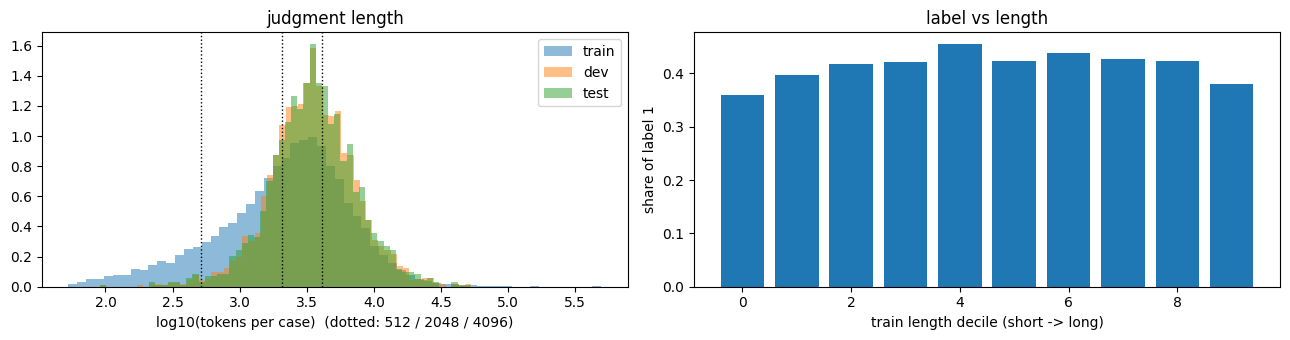

In [22]:
DATA = load_data(merge(DEFAULTS, {"data_dir": str(DATA_DIR), "out_dir": OUT_DIR, "cache_dir": CACHE_DIR, "max_docs": MAX_DOCS,
                                  "backbone": {"ckpt": FOUND.get("A2") or next(iter(FOUND.values()))}}))
if RUN_EDA:
    D.describe_raw(DATA_DIR)
    ST = D.stats(DATA)
    print(json.dumps(ST, indent=1))
    import numpy as np, matplotlib.pyplot as plt
    fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
    for split in ("train", "dev", "test"):
        ax[0].hist(np.log10([max(1, len(t)) for t in DATA[split]["tokens"]]), bins=60, alpha=0.5, label=split, density=True)
    for L in (512, 2048, 4096):
        ax[0].axvline(np.log10(L), color="k", ls=":", lw=1)
    ax[0].set_xlabel("log10(tokens per case)  (dotted: 512 / 2048 / 4096)"); ax[0].legend(); ax[0].set_title("judgment length")
    lens = np.array([len(t) for t in DATA["train"]["tokens"]]); y = DATA["train"]["labels"]
    bins = np.quantile(lens, np.linspace(0, 1, 11)); b = np.clip(np.digitize(lens, bins[1:-1]), 0, 9)
    ax[1].bar(range(10), [y[b == i].mean() if (b == i).any() else 0 for i in range(10)])
    ax[1].set_xlabel("train length decile (short -> long)"); ax[1].set_ylabel("share of label 1"); ax[1].set_title("label vs length")
    plt.tight_layout(); plt.show()

## Build the job list

In [23]:
def run_name(n):
    return n + TAG + ("_smoke" if SMOKE_TEST else "")

JOBS = []
for name in RUN_LIST:
    cfg = json.loads(json.dumps(EXPERIMENTS[name]))
    cfg.update(run_name=run_name(name), data_dir=str(DATA_DIR), out_dir=OUT_DIR, ckpt_root=CKPT_ROOT,
               cache_dir=CACHE_DIR, max_docs=MAX_DOCS)
    key = cfg["backbone"]["ckpt"].lstrip("@")
    if key not in FOUND:
        print(f"SKIP {name}: checkpoint @{key} not attached"); continue
    cfg["backbone"]["ckpt"] = FOUND[key]
    teacher = None
    if cfg.get("kd", {}).get("teacher_run"):
        teacher = run_name(os.path.basename(cfg["kd"]["teacher_run"]))
        cfg["kd"]["teacher_run"] = os.path.join(OUT_DIR, teacher)
        if teacher not in [run_name(n) for n in RUN_LIST] and not os.path.exists(os.path.join(OUT_DIR, teacher, "summary.json")):
            print(f"SKIP {name}: teacher {teacher} is neither in RUN_LIST nor finished earlier"); continue
    cfg.setdefault("train", {})["max_minutes"] = MAX_MINUTES
    for k, v in OVERRIDES.items():
        set_by_path(cfg, k, json.dumps(v))
    if SMOKE_TEST:
        cfg["backbone"]["keep_layers"] = 1 if not cfg["backbone"].get("keep_layers") else 2
        cfg["train"].update(epochs=1, docs_per_epoch=8)
    JOBS.append((cfg["run_name"], cfg, teacher))
for n, c, t in JOBS:
    ch = merge(DEFAULTS["chunks"], c.get("chunks", {}))
    print(f"  {n:28s} model {os.path.basename(os.path.dirname(c['backbone']['ckpt'])):22s} method {c['method']['name']:8s} "
          f"chunks {ch['k']}x{ch['len']} {ch['strategy']:8s}" + (f"  (teacher {t})" if t else ""))

  R1_A2_full_hier              model A_llama_decoder_v2     method full     chunks 4x512 headtail
  R2_B_adapter_hier            model B_encoder_decoder      method adapter  chunks 4x512 headtail
  R3_C_lorma_hier              model C_hybrid_prefix_mlm    method lorma    chunks 4x512 headtail
  X5_B_full_hier               model B_encoder_decoder      method full     chunks 4x512 headtail
  R4_KD_D6L_from_R1            model D_efficient_swa_mqa    method full     chunks 4x1024 headtail  (teacher R1_A2_full_hier)
  X1_A2_lorma_hier             model A_llama_decoder_v2     method lorma    chunks 4x512 headtail
  X3_A2_full_tail512           model A_llama_decoder_v2     method full     chunks 1x512 tail    
  X2_D_partial_long            model D_efficient_swa_mqa    method partial  chunks 4x1024 headtail
  X4_D6L_noKD                  model D_efficient_swa_mqa    method full     chunks 4x1024 headtail


## Run (parallel on 2 GPUs, otherwise sequential)

In [24]:
import time, traceback
os.makedirs(f"{OUT_DIR}/_jobs", exist_ok=True); os.makedirs(f"{OUT_DIR}/_logs", exist_ok=True)
KEEP = ("[epoch]", "[submit]", "[kd]", "[train]", "[model]", "[dev]", "[progress]", "early stop", "Error", "Traceback")

def finished(name):
    return os.path.exists(os.path.join(OUT_DIR, name, "summary.json"))

def run_parallel(jobs, gpus):
    pending, running, done, failed = list(jobs), {}, set(), set()
    t0 = time.time()
    while pending or running:
        for g in gpus:
            if g in running:
                continue
            for j in list(pending):
                name, cfg, teacher = j
                if teacher and teacher in failed:
                    print(f"SKIP {name}: teacher {teacher} failed"); pending.remove(j); failed.add(name); continue
                if teacher and not finished(teacher):
                    continue
                path = f"{OUT_DIR}/_jobs/{name}.json"
                json.dump(cfg, open(path, "w"), indent=1)
                log = open(f"{OUT_DIR}/_logs/{name}.log", "w")
                env = dict(os.environ, CUDA_VISIBLE_DEVICES=str(g), PYTHONUNBUFFERED="1")
                proc = subprocess.Popen([sys.executable, "-u", "-m", "p4cjpe.run", "--config", path],
                                        cwd=WORK, env=env, stdout=log, stderr=subprocess.STDOUT)
                running[g] = (name, proc, log, 0)
                pending.remove(j)
                print(f"[{time.time()-t0:6.0f}s] START {name} on GPU {g}")
                break
        time.sleep(15)
        for g, (name, proc, log, pos) in list(running.items()):
            txt = open(f"{OUT_DIR}/_logs/{name}.log").read()
            for line in txt[pos:].splitlines():
                if any(k in line for k in KEEP):
                    print(f"  [{name} @GPU{g}] {line}")
            running[g] = (name, proc, log, len(txt))
            if proc.poll() is not None:
                log.close(); del running[g]
                if proc.returncode == 0 and finished(name):
                    done.add(name); print(f"[{time.time()-t0:6.0f}s] DONE  {name}")
                else:
                    failed.add(name); print(f"[{time.time()-t0:6.0f}s] FAILED {name} (exit {proc.returncode}); log tail:")
                    print("\n".join(txt.splitlines()[-25:]))
        if pending and not running and all(t and not finished(t) for _, _, t in pending):
            for n, _, t in pending:
                print(f"SKIP {n}: teacher {t} never finished")
            break
    return done, failed

if PARALLEL and N_GPU >= 2:
    DONE, FAILED = run_parallel(JOBS, list(range(N_GPU)))
else:
    DONE, FAILED = set(), set()
    for name, cfg, teacher in JOBS:
        if teacher and not finished(teacher):
            print(f"SKIP {name}: teacher {teacher} not finished"); continue
        print(f"\n##################### {name} #####################")
        try:
            summary, model = run(cfg, data=DATA); del model; torch.cuda.empty_cache(); DONE.add(name)
        except Exception:
            traceback.print_exc(); FAILED.add(name)
            print(f">>> {name} FAILED; continuing")

os.makedirs(f"{WORK}/submissions", exist_ok=True)
for name in sorted(DONE):
    if name.endswith("_smoke"):
        continue
    s = json.load(open(os.path.join(OUT_DIR, name, "summary.json")))
    if s.get("submission"):
        shutil.copy(s["submission"], f"{WORK}/submissions/{name}.zip")
print("done:", sorted(DONE), "| failed:", sorted(FAILED))
print("submissions:", sorted(os.listdir(f"{WORK}/submissions")))

[     0s] START R1_A2_full_hier on GPU 0
[     0s] START R2_B_adapter_hier on GPU 1
  [R1_A2_full_hier @GPU0] [model] arch A (LlamaLM) | layers 11/11 | attention bidirectional | method full | chunks 4x512 headtail | pool attn/attn
  [R1_A2_full_hier @GPU0] [model] params total 93.91M | trainable 93.908M (100.0%) | class weights [0.854, 1.207]
  [R1_A2_full_hier @GPU0] [train] 3 epochs x 8000 cases | ~3.32 chunks/case | 1000 steps/epoch | 3000 steps | amp torch.float16 | time limit 80 min
  [R2_B_adapter_hier @GPU1] [model] arch B (EncDecLM) | layers 6/6 | attention bidirectional | method adapter | chunks 4x512 headtail | pool attn/attn
  [R2_B_adapter_hier @GPU1] [model] params total 43.30M | trainable 0.974M (2.249%) | class weights [0.854, 1.207]
  [R2_B_adapter_hier @GPU1] [train] 3 epochs x 8000 cases | ~3.32 chunks/case | 1000 steps/epoch | 3000 steps | amp torch.float16 | time limit 80 min
  [R2_B_adapter_hier @GPU1] [progress] epoch 1  20% | loss 0.7184 | 0.8 min | ETA all epoch

## Results table (also saved as `/kaggle/working/RESULTS.csv`)

In [25]:
import csv
import pandas as pd
rows = []
for p in sorted(glob.glob(f"{OUT_DIR}/*/summary.json")):
    s = json.load(open(p))
    if SMOKE_TEST != s["run"].endswith("_smoke"):
        continue
    m, ch = s["method"], s["chunks"]
    rows.append({"run": s["run"], "arch": s["arch"], "backbone": s["backbone"], "layers": s["layers"],
                 "method": m["name"] + ("+KD" if s.get("kd_teacher") else ""),
                 "doc_repr": f"{ch['k']}x{ch['len']} {ch['strategy']}", "pool": f"{s['head']['chunk_pool']}/{s['head']['agg']}",
                 "params_M": round(s["params_total"] / 1e6, 1), "trainable_M": round(s["params_trainable"] / 1e6, 3),
                 "trainable_%": s["trainable_pct"], "train_min": s["train_minutes"], "epochs": s["epochs_run"],
                 "best_epoch": s["best_epoch"], "peak_mem_GB": round(s["peak_train_mem_gb"] or 0, 2),
                 "docs_per_s": s["infer_docs_per_sec"],
                 "dev_F1@0.5": round(s["dev"]["macro_f1"], 4), "thr": s["threshold"],
                 "dev_macroF1": round(s["dev_calibrated"]["macro_f1"], 4), "dev_macroP": round(s["dev_calibrated"]["macro_p"], 4),
                 "dev_macroR": round(s["dev_calibrated"]["macro_r"], 4), "dev_acc": round(s["dev_calibrated"]["accuracy"], 4),
                 "test_pred1": s.get("test_share_pred_1")})
if rows:
    with open(f"{WORK}/RESULTS.csv", "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=list(rows[0])); w.writeheader(); w.writerows(rows)
    RES = pd.DataFrame(rows).sort_values("dev_macroF1", ascending=False)
    display(RES)
    print("dev_macroF1 = macro-F1 at the dev-calibrated threshold (used for the submission); dev_F1@0.5 = plain argmax")

,run,arch,backbone,layers,method,doc_repr,pool,params_M,trainable_M,trainable_%,...,best_epoch,peak_mem_GB,docs_per_s,dev_F1@0.5,thr,dev_macroF1,dev_macroP,dev_macroR,dev_acc,test_pred1
0,R1_A2_full_hier,A,A_llama_decoder_v2,11,full,4x512 headtail,attn/attn,93.9,93.908,100.000,...,2,8.12,28.17,0.7089,0.51,0.7105,0.7105,0.7105,0.7105,0.514
4,X1_A2_lorma_hier,A,A_llama_decoder_v2,11,lorma,4x512 headtail,attn/attn,95.1,1.325,1.393,...,3,7.23,22.71,0.6792,0.38,0.7072,0.7074,0.7072,0.7073,0.519
3,R4_KD_D6L_from_R1,D,D_efficient_swa_mqa,6,full+KD,4x1024 headtail,attn/attn,45.9,45.892,100.000,...,3,1.62,35.01,0.6838,0.39,0.7057,0.7059,0.7057,0.7057,0.489
7,X4_D6L_noKD,D,D_efficient_swa_mqa,6,full,4x1024 headtail,attn/attn,45.9,45.892,100.000,...,3,1.62,34.00,0.6510,0.37,0.6789,0.6792,0.6790,0.6790,0.525
6,X3_A2_full_tail512,A,A_llama_decoder_v2,11,full,1x512 tail,attn/attn,93.9,93.908,100.000,...,3,4.66,114.37,0.6717,0.43,0.6766,0.6766,0.6766,0.6766,0.513
8,X5_B_full_hier,B,B_encoder_decoder,6,full,4x512 headtail,attn/attn,42.4,42.409,100.000,...,3,3.57,71.38,0.6367,0.41,0.6432,0.6440,0.6435,0.6436,0.545
5,X2_D_partial_long,D,D_efficient_swa_mqa,12,partial,4x1024 headtail,attn/attn,71.2,16.972,23.832,...,3,1.31,17.70,0.6207,0.42,0.6384,0.6384,0.6384,0.6384,0.512
1,R2_B_adapter_hier,B,B_encoder_decoder,6,adapter,4x512 headtail,attn/attn,43.3,0.974,2.249,...,1,2.47,72.85,0.5774,0.50,0.5774,0.5775,0.5775,0.5775,0.498
2,R3_C_lorma_hier,C,C_hybrid_prefix_mlm,10,lorma,4x512 headtail,attn/attn,71.2,1.155,1.623,...,3,6.16,31.99,0.5036,0.50,0.5036,0.5092,0.5088,0.5086,0.397


dev_macroF1 = macro-F1 at the dev-calibrated threshold (used for the submission); dev_F1@0.5 = plain argmax


## Ensemble → one more submission

In [26]:
if ENSEMBLE == "auto":
    members = list(RES["run"][:3]) if rows else []
else:
    members = [run_name(n) for n in ENSEMBLE]
members = [m for m in members if finished(m)]
if len(members) >= 2:
    es = ensemble([f"{OUT_DIR}/{r}" for r in members], f"{OUT_DIR}/ENS{TAG}" + ("_smoke" if SMOKE_TEST else ""), DATA)
    print("ensemble", members, "| dev macro-F1", round(es["dev_calibrated"]["macro_f1"], 4), "at threshold", es["threshold"])
    if not SMOKE_TEST:
        shutil.copy(es["submission"], f"{WORK}/submissions/ENS{TAG}.zip")
else:
    print("ensemble skipped (needs >= 2 finished members); members found:", members)
print(sorted(os.listdir(f"{WORK}/submissions")))

ensemble of ['R1_A2_full_hier', 'X1_A2_lorma_hier', 'R4_KD_D6L_from_R1'] | threshold 0.44
class         P      R     F1   gold   pred
0         0.720  0.735  0.727   1252   1278
1         0.731  0.716  0.723   1259   1233
MACRO     0.725  0.725  0.725   (accuracy 0.725, 2511 cases, confusion [[TN FP] [FN TP]] = [[920, 332], [358, 901]])
ensemble ['R1_A2_full_hier', 'X1_A2_lorma_hier', 'R4_KD_D6L_from_R1'] | dev macro-F1 0.7252 at threshold 0.44
['ENS.zip', 'R1_A2_full_hier.zip', 'R2_B_adapter_hier.zip', 'R3_C_lorma_hier.zip', 'R4_KD_D6L_from_R1.zip', 'X1_A2_lorma_hier.zip', 'X2_D_partial_long.zip', 'X3_A2_full_tail512.zip', 'X4_D6L_noKD.zip', 'X5_B_full_hier.zip']


## Which parts of a judgment carry the outcome? (section analysis)

In [27]:
import pandas as pd
SEC = {}
for n in SECTION_RUNS:
    r = run_name(n)
    if not finished(r):
        print("skip", r, "(not finished)"); continue
    SEC[r] = section_analysis(f"{OUT_DIR}/{r}", DATA, "cuda" if N_GPU else "cpu", max_docs=SECTION_MAX_DOCS)
    print(r); display(pd.DataFrame(SEC[r]["views"]))
    att = SEC[r]["chunk_attention_by_position(uniform 8 chunks)"]
    if att:
        print("chunk attention by relative position:", att)

R1_A2_full_hier


,view,chunks,macro_f1,accuracy,pred_1_share
0,first 512 (head),1 x 512 head,0.5077,0.5467,0.775
1,middle 512,1 x 512 middle,0.5758,0.5780,0.421
2,last 512 (tail),1 x 512 tail,0.6712,0.6713,0.471
3,head 2 chunks,2 x 512 head,0.5746,0.5827,0.631
4,tail 2 chunks,2 x 512 tail,0.6813,0.6813,0.486
5,trained view,4 x 512 headtail,0.7020,0.7020,0.500
6,tail 4 chunks,4 x 512 tail,0.6933,0.6933,0.479
7,uniform 4 chunks,4 x 512 uniform,0.6947,0.6947,0.499
8,uniform 8 chunks,8 x 512 uniform,0.7139,0.7140,0.515


chunk attention by relative position: {'0.00-0.12': 0.397, '0.12-0.25': 0.631, '0.25-0.38': 0.751, '0.38-0.50': 0.817, '0.50-0.62': 0.892, '0.62-0.75': 0.911, '0.75-0.88': 1.082, '0.88-1.00': 2.141}


## Error analysis of the best run (or set `RUN`): false positives / false negatives

In [28]:
RUN = RES.iloc[0]["run"] if rows else None
if RUN:
    import numpy as np
    import matplotlib.pyplot as plt
    from p4cjpe.metrics import format_report
    rep = json.load(open(f"{OUT_DIR}/{RUN}/dev_report.json"))
    print(RUN); print(format_report(rep["calibrated"], f"dev at threshold {rep['threshold']}"))
    P = pd.DataFrame(json.load(open(f"{OUT_DIR}/{RUN}/dev_predictions.json")))
    P["kind"] = np.select([(P.gold == 1) & (P.pred == 1), (P.gold == 0) & (P.pred == 0), (P.gold == 0) & (P.pred == 1)],
                          ["TP", "TN", "FP"], "FN")
    print("\nby outcome type (token length, confidence):")
    display(P.groupby("kind").agg(cases=("id", "size"), median_tokens=("n_tokens", "median"), mean_prob1=("prob1", "mean")))
    P["len_bin"] = pd.qcut(P.n_tokens, 5, duplicates="drop")
    P["correct"] = P.gold == P.pred
    print("accuracy by judgment length (quintiles):")
    display(P.groupby("len_bin", observed=True).agg(cases=("id", "size"), accuracy=("correct", "mean"), share_gold_1=("gold", "mean")))
    fig, ax = plt.subplots(1, 3, figsize=(18, 4))
    for g in (0, 1):
        ax[0].hist(P.prob1[P.gold == g], bins=30, alpha=0.6, label=f"gold {g}")
    ax[0].axvline(rep["threshold"], color="k", ls="--"); ax[0].legend(); ax[0].set_title(f"{RUN}: P(label 1) on dev")
    for r in rows:
        h = json.load(open(f"{OUT_DIR}/{r['run']}/history.json"))
        ax[1].plot([x["epoch"] for x in h], [x["train_loss"] for x in h], "o-", label=r["run"], ms=3)
        ax[2].plot([x["epoch"] for x in h], [x["dev_macro_f1"] for x in h], "o-", label=r["run"], ms=3)
    ax[1].set_title("train loss"); ax[2].set_title("dev macro-F1 (argmax)"); ax[2].legend(fontsize=7)
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/analysis_{RUN}.png", dpi=120); plt.show()
    dev_text = {c["id"]: c["text"] for c in D.load_split(DATA_DIR, "dev", MAX_DOCS)}
    for kind in ("FP", "FN"):
        sub = P[P.kind == kind].assign(conf=lambda d: (d.prob1 - 0.5).abs()).sort_values("conf", ascending=False).head(2)
        for _, r in sub.iterrows():
            t = dev_text[r.id]
            print(f"\n--- {kind} {r.id} | gold {r.gold} | P(1) {r.prob1:.3f} | {r.n_tokens} tokens\n  START: {t[:300]}\n  END:   ...{t[-400:]}")

R1_A2_full_hier


KeyError: 0

## Efficiency: model size, memory and inference cost

In [ ]:
if rows:
    E = RES[["run", "arch", "method", "layers", "params_M", "trainable_M", "trainable_%", "peak_mem_GB", "train_min",
             "docs_per_s", "dev_macroF1"]].copy()
    best = E.dev_macroF1.max()
    E["F1_vs_best"] = (E.dev_macroF1 - best).round(4)
    display(E.sort_values("params_M"))
    for n in RUN_LIST:
        r = run_name(n)
        if finished(r) and os.path.exists(f"{OUT_DIR}/{r}/teacher.json"):
            t = json.load(open(f"{OUT_DIR}/{r}/teacher.json")); s = json.load(open(f"{OUT_DIR}/{r}/summary.json"))
            print(f"KD {r}: student {s['params_total']/1e6:.1f}M params, dev F1 {s['dev_calibrated']['macro_f1']:.4f} | "
                  f"teacher {t['teacher_backbone']} {(t['teacher_params'] or 0)/1e6:.1f}M params, dev F1(argmax) {t['teacher_dev_macro_f1']}")

## Download / submit